---
# HMM OT - Figures & Supplementary Analyses
---

## Imports

In [4]:
# Standard I/O
import io
import json
import os
import warnings
from pathlib import Path
from itertools import groupby

# Numerics and data
import numpy as np
import pandas as pd

# Plotting
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import cm, gridspec
from matplotlib.colors import ListedColormap, Normalize
from matplotlib.patches import Ellipse
from mpl_toolkits.axes_grid1 import make_axes_locatable
from statannotations.Annotator import Annotator
from nilearn.datasets import fetch_atlas_schaefer_2018
from matplotlib.ticker import ScalarFormatter, FuncFormatter, LinearLocator
from matplotlib.lines import Line2D
from PIL import Image
from matplotlib.text import Text

# Statistics
import statsmodels.api as sm
from scipy.optimize import linear_sum_assignment
from scipy.stats import chi2, chi2_contingency, mannwhitneyu, permutation_test, spearmanr, ttest_ind
from statsmodels.stats.multitest import multipletests
from scipy import stats

# Machine learning, clustering and embeddings
import umap
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import MDS
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Neuroimaging, surfaces and parcellations
from brainspace.datasets import load_parcellation
from enigmatoolbox.utils.parcellation import parcel_to_surface
from netneurotools import datasets as nntdata
from neuromaps.datasets import fetch_fslr
from neuromaps.images import dlabel_to_gifti
from neuromaps.parcellate import Parcellater
from surfplot import Plot

# Warnings
warnings.filterwarnings("ignore", category=FutureWarning)

## Data Utils

In [5]:
def load_main_results(main_dir):
    '''
    Load the saved outputs from the primary HMM-OT analysis.
    '''
    main_dir = Path(main_dir)

    with np.load(main_dir / "hmm_parameters.npz") as data:
        hmm_parameters = {key: data[key] for key in data.files}

    return {
        "gamma_seq": np.load(main_dir / "gamma_seq.npy"),
        "path_seq": np.load(main_dir / "path_seq.npy"),
        "hmm_metrics": pd.read_csv(main_dir / "hmm_metrics.csv"),
        "means_orig": np.load(main_dir / "means_orig.npy"),
        "covs_orig": np.load(main_dir / "covs_orig.npy"),
        "fcs_orig": np.load(main_dir / "fcs_orig.npy"),
        "hmm_reconstructed_fc": np.load(main_dir / "hmm_reconstructed_fc.npy"),
        "Q_all": np.load(main_dir / "Q_all.npy"),
        "cost_matrix_dir": np.load(main_dir / "cost_matrix_dir.npy"),
        "clusters_assignment": pd.read_csv(main_dir / "clusters_assignment.csv"),
        "hmm_parameters": hmm_parameters,
        "hmm_restart_table": pd.read_csv(main_dir / "hmm_restart_table.csv"),
        "hmm_em_trace": np.load(main_dir / "hmm_em_trace.npy"),
        "hmm_group_comparison": pd.read_csv(main_dir / "hmm_group_comparison.csv"),
        "hmm_clinical_correlations": pd.read_csv(main_dir / "hmm_clinical_correlations.csv"),
        "state_signal_qc": pd.read_csv(main_dir / "state_signal_qc.csv"),
        "bad_frame_probabilities": pd.read_csv(main_dir / "bad_frame_probabilities.csv"),
        "clusters_comparison": pd.read_csv(main_dir / "clusters_comparison.csv"),
        "clusters_comparison_adjusted": pd.read_csv(main_dir / "clusters_comparison_adjusted.csv"),
        "hmm_crossval_zeromean": pd.read_csv(main_dir / "hmm_crossval_zeromean.csv"),
        "hmm_crossval_freemean": pd.read_csv(main_dir / "hmm_crossval_freemean.csv"),
    }


def load_supp_results(supp_dir, M, K, zero_mean):
    '''
    Load one supplementary HMM-OT configuration.
    '''
    model_name = "zeromean" if zero_mean else "freemean"
    run_dir = Path(supp_dir) / f"M{M}_K{K:02d}" / model_name

    with np.load(run_dir / "hmm_parameters.npz") as data:
        hmm_parameters = {key: data[key] for key in data.files}

    return {
        "gamma_seq": np.load(run_dir / "gamma_seq.npy"),
        "path_seq": np.load(run_dir / "path_seq.npy"),
        "hmm_metrics": pd.read_csv(run_dir / "hmm_metrics.csv"),
        "means_orig": np.load(run_dir / "means_orig.npy"),
        "covs_orig": np.load(run_dir / "covs_orig.npy"),
        "fcs_orig": np.load(run_dir / "fcs_orig.npy"),
        "hmm_reconstructed_fc": np.load(run_dir / "hmm_reconstructed_fc.npy"),
        "Q_all": np.load(run_dir / "Q_all.npy"),
        "cost_matrix_dir": np.load(run_dir / "cost_matrix_dir.npy"),
        "clusters_assignment": pd.read_csv(run_dir / "clusters_assignment.csv"),
        "hmm_parameters": hmm_parameters,
        "hmm_restart_table": pd.read_csv(run_dir / "hmm_restart_table.csv"),
        "hmm_em_trace": np.load(run_dir / "hmm_em_trace.npy"),
    }

## Plotting Utils

In [6]:
def plot_matrices(matrices, network_labels=None, network_names=None, titles=None, vminvmax=[[-1, 1]], center=None, cmap="RdBu_r",
                  figsize_per_matrix=(5, 4), sort=True, labels_for=None, dataset=None, label_pad_x=1.5, label_pad_y=1.5, label_size=3.0,
                  x_label_shift=0.0, y_label_shift=0.0, axes=None, cbar=True):
    if dataset is not None:
        network_labels = dataset.network_labels
        network_names = dataset.network_names

    num_matrices = len(matrices)

    if axes is None:
        fig, axes = plt.subplots(1, num_matrices, figsize=(figsize_per_matrix[0] * num_matrices, figsize_per_matrix[1]), constrained_layout=True)
        if num_matrices == 1:
            axes = [axes]
    else:
        if num_matrices == 1:
            axes = [axes] if not isinstance(axes, (list, tuple, np.ndarray)) else list(np.ravel(axes))
        else:
            axes = list(np.ravel(axes))

    labels_available = (network_labels is not None) and (network_names is not None)

    if labels_for is None:
        label_mask = [True] * num_matrices
    else:
        if isinstance(labels_for, (list, tuple)) and len(labels_for) == num_matrices and all(isinstance(x, (bool, np.bool_)) for x in labels_for):
            label_mask = list(labels_for)
        else:
            label_mask = [False] * num_matrices
            for idx in labels_for:
                label_mask[int(idx)] = True

    tick_positions, label_positions, tick_labels = [], [], []

    if labels_available and network_labels is not None and network_names is not None:
        network_labels = np.array(network_labels)
        network_names = list(network_names)

        if sort:
            _, sorted_labels = np.unique(network_labels, return_inverse=True)
            sorted_indices = np.argsort(sorted_labels, kind="stable")
            labels_sorted = sorted_labels[sorted_indices]
        else:
            sorted_indices = np.arange(len(network_labels))
            labels_sorted = network_labels

        prev_label = labels_sorted[0]
        start = 0
        tick_positions.append(0)

        for j, label in enumerate(labels_sorted):
            if label != prev_label:
                tick_positions.append(j)
                label_positions.append((start + j) / 2)
                tick_labels.append(network_names[prev_label])
                start = j
                prev_label = label

        tick_positions.append(len(labels_sorted))
        label_positions.append((start + len(labels_sorted)) / 2)
        tick_labels.append(network_names[prev_label])
    else:
        sorted_indices = None

    tick_positions = sorted(list(set(tick_positions)))
    label_fontsize = max(6, min(12, figsize_per_matrix[0] * label_size))

    for i, (matrix, ax) in enumerate(zip(matrices, axes)):
        if labels_available and sort:
            mat_to_plot = matrix[np.ix_(sorted_indices, sorted_indices)]  # type:ignore
        else:
            mat_to_plot = matrix

        vmin = vminvmax[i][0]
        vmax = vminvmax[i][1]

        heatmap = sns.heatmap(mat_to_plot, ax=ax, cmap=cmap, center=center, vmin=vmin, vmax=vmax, square=True, xticklabels=False, yticklabels=False,
                              cbar=cbar, cbar_kws={"shrink": 1, "pad": 0.05})

        colorbar = heatmap.collections[0].colorbar
        if colorbar is not None:
            if np.min(mat_to_plot) <= 0:
                colorbar.set_ticks([vmin, 0, vmax])
                colorbar.set_ticklabels([f"{vmin:.1f}", "0", f"{vmax:.1f}"])
            else:
                colorbar.set_ticks([vmin, vmax])
                colorbar.set_ticklabels([f"{vmin:.1f}", f"{vmax:.1f}"])

            colorbar.outline.set_edgecolor("black")  # type:ignore
            colorbar.outline.set_linewidth(0.5)  # type:ignore
            colorbar.ax.tick_params(labelsize=10)

        if labels_available and label_mask[i]:
            ax.set_xticks(tick_positions)
            ax.set_yticks(tick_positions)
            ax.set_xticklabels([])
            ax.set_yticklabels([])

            for pos, label in zip(label_positions, tick_labels):
                ax.text(pos + x_label_shift, ax.get_ylim()[0] + label_pad_x, label, ha="center", va="top", fontsize=label_fontsize, rotation=90)
                ax.text(ax.get_xlim()[0] - label_pad_y, pos + y_label_shift, label, ha="right", va="center", fontsize=label_fontsize)

        ax.tick_params(axis="both", length=3, width=0.8, labelsize=10)

        if titles and i < len(titles):
            ax.set_title(titles[i], fontsize=14)

        for spine_name in ax.spines:
            ax.spines[spine_name].set_visible(True)
            ax.spines[spine_name].set_edgecolor("black")
            ax.spines[spine_name].set_linewidth(0.5)


def add_cov_ellipse(ax, x, y, color, alpha=0.18, lw=1.2):
    '''
    Add a 95% covariance ellipse and centroid to a 2D scatter plot.
    '''
    x = np.asarray(x, float)
    y = np.asarray(y, float)

    if x.size < 3:
        return

    cov = np.cov(x, y)
    vals, vecs = np.linalg.eigh(cov)
    order = np.argsort(vals)[::-1]
    vals, vecs = vals[order], vecs[:, order]

    r2 = chi2.ppf(0.95, df=2)
    w, h = 2 * np.sqrt(np.maximum(vals, 0) * r2)
    angle = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0]))
    center = (x.mean(), y.mean())

    ax.add_patch(Ellipse(center, width=w, height=h, angle=angle,
                         facecolor=color, edgecolor=color, alpha=alpha, lw=lw))
    ax.scatter(*center, s=80, marker="*", color=color,
               edgecolors="black", linewidths=0.6, zorder=5)
   


def render_surface_image(parcel_data, n_parc, lh_surf, rh_surf, lh_parc, rh_parc,
                         surface_space="conte69", cmap="RdBu_r", color_range=(-0.05, 0.05), dpi=300):
    '''
    Render parcel-wise values on the cortical surface and return the rasterized image.
    '''
    surf_data = parcel_to_surface(parcel_data, f"schaefer_{n_parc}_{surface_space}")
    half = len(surf_data) // 2
    data_lh, data_rh = surf_data[:half], surf_data[half:]

    p = Plot(lh_surf, rh_surf)
    p.add_layer({"left": data_lh, "right": data_rh}, cmap=cmap, cbar=False, color_range=color_range)
    p.add_layer({"left": lh_parc, "right": rh_parc}, cmap="gray", as_outline=True, cbar=False)

    fig_state = p.build(scale=(10, 10), colorbar=False)

    buffer = io.BytesIO()
    fig_state.savefig(buffer, format="png", dpi=dpi, bbox_inches="tight")
    buffer.seek(0)
    img = mpimg.imread(buffer).copy()

    plt.close(fig_state)
    buffer.close()

    return img


def add_surface_colorbars(fig, axes, color_ranges, cmap="RdBu_r", mode="shared", orientation="horizontal",
                          pad=0.014, thickness=0.012, length=0.72, label=r"$\Delta$FC",
                          ticksize=8, labelsize=10):
    '''
    Add shared or separate colorbars to cortical surface-map axes.
    '''
    mode = str(mode).lower()
    orientation = str(orientation).lower()

    if mode == "none":
        return []

    if mode not in {"shared", "separate"}:
        raise ValueError("surface_cbar_mode must be 'shared', 'separate', or 'none'.")

    if orientation not in {"horizontal", "vertical"}:
        raise ValueError("surface_cbar_orientation must be 'horizontal' or 'vertical'.")

    if len(axes) != len(color_ranges):
        raise ValueError("The number of axes and color ranges must match.")

    if mode == "shared":
        reference_range = np.asarray(color_ranges[0], float)

        if not all(np.allclose(reference_range, np.asarray(color_range, float)) for color_range in color_ranges[1:]):
            raise ValueError("A shared colorbar requires a shared surface scale.")

    def create_colorbar(selected_axes, color_range):
        positions = [ax.get_position() for ax in selected_axes]
        x0 = min(pos.x0 for pos in positions)
        x1 = max(pos.x1 for pos in positions)
        y0 = min(pos.y0 for pos in positions)
        y1 = max(pos.y1 for pos in positions)

        if orientation == "horizontal":
            cbar_length = (x1 - x0) * length
            cbar_x = (x0 + x1 - cbar_length) / 2
            cbar_y = y0 - pad - thickness
            cax = fig.add_axes([cbar_x, cbar_y, cbar_length, thickness])
        else:
            cbar_length = (y1 - y0) * length
            cbar_x = x1 + pad
            cbar_y = (y0 + y1 - cbar_length) / 2
            cax = fig.add_axes([cbar_x, cbar_y, thickness, cbar_length])

        sm = cm.ScalarMappable(norm=Normalize(vmin=color_range[0], vmax=color_range[1]), cmap=cmap)
        sm.set_array([])

        cbar = fig.colorbar(sm, cax=cax, orientation=orientation)
        cbar.set_label(label, fontsize=labelsize, labelpad=3 if orientation == "horizontal" else 8)
        cbar.ax.tick_params(labelsize=ticksize)
        cbar.outline.set_edgecolor("black")  # type: ignore
        cbar.outline.set_linewidth(0.5)  # type: ignore

        return cbar

    if mode == "shared":
        return [create_colorbar(axes, color_ranges[0])]

    return [create_colorbar([ax], color_range) for ax, color_range in zip(axes, color_ranges)]


def convert_tiff_to_rgb(path, print_check=False, fig=None):
    '''
    Convert a TIFF image to RGB format, preserving the original DPI.
    '''
    with Image.open(path) as im:
        dpi = im.info.get("dpi")
        rgba = im.convert("RGBA")
        rgb = Image.new("RGB", rgba.size, "white")
        rgb.paste(rgba, mask=rgba.getchannel("A"))

    kwargs = {"format": "TIFF", "compression": "tiff_lzw"}
    if dpi is not None:
        kwargs["dpi"] = dpi
    rgb.save(path, **kwargs)

    if print_check:
        with Image.open(path) as im:
            dx, dy = im.info["dpi"]
            print("Size (cm):", round(im.width / dx * 2.54, 2), round(im.height / dy * 2.54, 2))
            print("DPI:", im.info["dpi"])
            print("Mode:", im.mode)
            print("Compression:", im.info["compression"])
            print("File size (MB):", round(path.stat().st_size / 1e6, 2))
            if fig is not None:
                fig.canvas.draw()
                bad_fonts = [(t.get_text(), t.get_fontsize()) for t in fig.findobj(match=Text)
                     if t.get_visible() and t.get_text().strip() and not 8 <= t.get_fontsize() <= 12]
                if len(bad_fonts) > 0:
                    print("Fonts outside 8-12 pt:", bad_fonts)

## Load Data

In [9]:
# Project directories
PROJECT_DIR = Path(r"C:\Users\lucat\Desktop\PNC\Codes\hmm_ot_project")
DATA_DIR = PROJECT_DIR / "data"
MAIN_DATA_DIR = DATA_DIR / "main"
SUPP_DATA_DIR = DATA_DIR / "supp"
FIG_DIR = PROJECT_DIR / "figures"

# Global parameters
TR = 1.5
T_PER_SUBJ = 240
N_PARCELS = 100

# Shared data
df_sel = pd.read_csv(DATA_DIR / "sel_features.csv", index_col="participant_id")
parcel_names = np.load(DATA_DIR / "parcel_names.npy")
network_labels = np.load(DATA_DIR / "network_labels.npy")
network_names = np.load(DATA_DIR / "network_names.npy")
fcs_all = np.load(DATA_DIR / "fcs_all.npy")

# Main results
main = load_main_results(MAIN_DATA_DIR)

# Global derived variables
subjects = df_sel.index.to_numpy()
n_subjects = len(subjects)

groups = df_sel["group"].map(lambda value: str(value).upper()).to_numpy()
ms_mask = groups == "MS"
hc_mask = groups == "HC"

selected_n_states = main["fcs_orig"].shape[0]

## Panels

In [10]:
def get_parcel_idx(parcel_names, include_all=None, include_any=None):
    '''
    Return parcel indices matching required and optional name substrings.
    '''
    include_all = [] if include_all is None else include_all
    include_any = [] if include_any is None else include_any

    idx = []

    for i, name in enumerate(parcel_names):
        cond_all = all(value in name for value in include_all)
        cond_any = True if len(include_any) == 0 else any(value in name for value in include_any)

        if cond_all and cond_any:
            idx.append(i)

    return np.asarray(idx, dtype=int)


def mean_seed_profile(fc_matrix, seed_idx, exclude_seed=True):
    '''
    Compute the mean seed-to-brain FC profile across selected seed parcels.
    '''
    profile = fc_matrix[seed_idx].mean(axis=0)

    if exclude_seed:
        profile = profile.copy()
        profile[seed_idx] = 0.0

    return profile


def symmetric_percentile_range(values, percentile=99):
    '''
    Compute a symmetric color range from an absolute-value percentile.
    '''
    values = np.asarray(values, float)
    finite_values = values[np.isfinite(values)]

    if finite_values.size == 0:
        return -1.0, 1.0

    vmax = float(np.percentile(np.abs(finite_values), percentile))

    if vmax <= 0:
        vmax = float(np.finfo(float).eps)

    return -vmax, vmax


def p_text(p):
    '''
    Format an uncorrected p-value with significance stars.
    '''
    if p < 0.001:
        return r"$p < 0.001$ ***"
    elif p < 0.01:
        return r"$p < 0.01$ **"
    elif p < 0.05:
        return r"$p < 0.05$ *"
    else:
        return r"$p \geq 0.05$"


def significance_stars(p):
    '''
    Return significance stars for a p-value.
    '''
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return ""


def p_annotation_fdr(p):
    '''
    Format an FDR-corrected p-value for plot annotations.
    '''
    if p < 0.001:
        return "***"

    return rf"$p_{{\mathrm{{FDR}}}} = {p:.3f}$ {significance_stars(p)}"


def p_text_fdr(p):
    '''
    Format an FDR-corrected p-value with significance stars.
    '''
    if p < 0.001:
        return r"$p_{\mathrm{FDR}} < 0.001$ ***"

    stars = significance_stars(p)
    return rf"$p_{{\mathrm{{FDR}}}} = {p:.3f}$" + (f" {stars}" if stars else "")

In [11]:
# Style settings
plt.style.use("tableau-colorblind10")

plt.rcParams["figure.autolayout"] = True
plt.rcParams["font.size"] = 12
plt.rcParams["axes.titlesize"] = 10
plt.rcParams["axes.labelsize"] = 12
plt.rcParams["xtick.labelsize"] = 9
plt.rcParams["ytick.labelsize"] = 9

FONT = "Arial"  # Change this to desired font

plt.rcParams.update({
    "figure.autolayout": False,
    "font.family": FONT,
    "font.size": 12,
    "axes.titlesize": 10,
    "axes.labelsize": 12,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "figure.titlesize": 12,
    "figure.labelsize": 12,
    "mathtext.fontset": "custom",
    "mathtext.rm": FONT,
    "mathtext.it": f"{FONT}:italic",
    "mathtext.bf": f"{FONT}:bold",
    "mathtext.bfit": f"{FONT}:bold:italic",
    "mathtext.sf": FONT,
    "mathtext.tt": FONT,
    "mathtext.cal": FONT,
    "mathtext.default": "regular",
    "mathtext.fallback": None,
    "axes.formatter.use_mathtext": False,
    "text.usetex": False,
    "axes.spines.right": False,
    "axes.spines.top": False
})

### Panel 2

In [43]:
# Panel data
fc_reconstructed = main["hmm_reconstructed_fc"]
fcs_orig = main["fcs_orig"]
transition_matrix = main["hmm_parameters"]["transition_matrix"]

selected_n_states = transition_matrix.shape[0]

# State-specific deviations from the global HMM reconstructed FC
delta_fc = fcs_orig - fc_reconstructed[None, :, :]

# Exit probabilities
exit_matrix = transition_matrix.copy()
np.fill_diagonal(exit_matrix, 0.0)

row_sum = exit_matrix.sum(axis=1, keepdims=True)
exit_matrix = np.divide(exit_matrix, row_sum, out=np.zeros_like(exit_matrix), where=row_sum != 0)

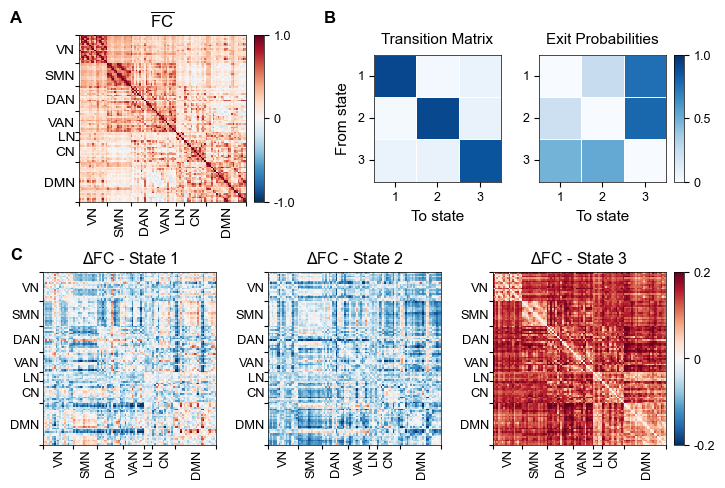

In [44]:
# Plot settings
sort_fc = True
sort_delta = True

labels_for_fc = [0]
labels_for_delta = list(range(selected_n_states))

transition_order = ["transition", "exit"]    # or ["exit", "transition"]

fc_cmap = "RdBu_r"
delta_cmap = "RdBu_r"
transition_cmap = "Blues"

fc_vmin, fc_vmax = -1.0, 1.0
delta_vmax = 0.2
transition_vmin, transition_vmax = 0.0, 1.0

fc_vminvmax = [[fc_vmin, fc_vmax]]
delta_vminvmax = [[-delta_vmax, delta_vmax] for _ in range(selected_n_states)]

fc_title = r"$\overline{\mathrm{FC}}$"
delta_titles = [rf"$\Delta$FC - State {i + 1}" for i in range(selected_n_states)]
transition_titles = {"transition": "Transition Matrix", "exit": "Exit Probabilities"}
state_numbers = [str(i + 1) for i in range(selected_n_states)]

annot_transition = False

# Network label positioning
label_pad_x_fc = 2.2
label_pad_y_fc = 2.2
x_label_shift_fc = 0.82
y_label_shift_fc = 0.82

label_pad_x_delta = 2.2
label_pad_y_delta = 2.2
x_label_shift_delta = 0.82
y_label_shift_delta = 0.82

# Manual colorbar controls
cbar_width = 0.015
cbar_pad = 0.012
fc_cbar_height = 1
transition_cbar_height = 1
delta_cbar_height = 1

# Disable automatic tight layout from rcParams
previous_autolayout = plt.rcParams["figure.autolayout"]
plt.rcParams["figure.autolayout"] = False

# Figure layout
fig = plt.figure(figsize=(17/2.54, 12.28/2.54))
outer_gs = gridspec.GridSpec(2, 1, figure=fig, height_ratios=[1, 1.10], hspace=0.37)

top_gs = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=outer_gs[0], width_ratios=[1.10, 1.35], wspace=0.35)
ax_fc = fig.add_subplot(top_gs[0, 0])

transition_gs = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=top_gs[0, 1], wspace=0.3)
axes_transition = [fig.add_subplot(transition_gs[0, i]) for i in range(2)]

delta_gs = gridspec.GridSpecFromSubplotSpec(1, selected_n_states, subplot_spec=outer_gs[1], wspace=0.3)
axes_delta = [fig.add_subplot(delta_gs[0, i]) for i in range(selected_n_states)]

fig.subplots_adjust(left=0.00, right=0.93, bottom=0.08, top=0.94)

# Panel A: Average FC
plot_matrices([fc_reconstructed], network_labels=network_labels, network_names=network_names, titles=[fc_title], vminvmax=fc_vminvmax,
              center=0, cmap=fc_cmap, figsize_per_matrix=(3.2, 3.0), sort=sort_fc, labels_for=labels_for_fc, label_pad_x=label_pad_x_fc,
              label_pad_y=label_pad_y_fc, label_size=3.1, x_label_shift=x_label_shift_fc, y_label_shift=y_label_shift_fc, axes=ax_fc, cbar=False)

ax_fc.set_title(fc_title, fontsize=12, pad=6)

# Panel B: Transition matrices
transition_data = {"transition": transition_matrix, "exit": exit_matrix}

for i, (ax, key) in enumerate(zip(axes_transition, transition_order)):
    sns.heatmap(transition_data[key], ax=ax, cmap=transition_cmap, vmin=transition_vmin, vmax=transition_vmax, square=True, cbar=False,
                annot=annot_transition, fmt=".2f", annot_kws={"fontsize": 8}, xticklabels=state_numbers, yticklabels=state_numbers,
                linewidths=0.5, linecolor="white")

    ax.set_title(transition_titles[key], fontsize=11.0, pad=8)
    ax.set_xlabel("To state", fontsize=11)
    ax.set_ylabel("From state" if i == 0 else "", fontsize=11, labelpad=5)
    ax.tick_params(axis="x", labelrotation=0, labelsize=9)
    ax.tick_params(axis="y", labelrotation=0, labelsize=9)

    for spine_name in ax.spines:
        ax.spines[spine_name].set_visible(True)
        ax.spines[spine_name].set_edgecolor("black")
        ax.spines[spine_name].set_linewidth(0.5)

# Panel C: Delta FC
plot_matrices(list(delta_fc[:selected_n_states]), network_labels=network_labels, network_names=network_names, titles=delta_titles,
              vminvmax=delta_vminvmax, center=0, cmap=delta_cmap, figsize_per_matrix=(2.9, 2.8), sort=sort_delta, labels_for=labels_for_delta,
              label_pad_x=label_pad_x_delta, label_pad_y=label_pad_y_delta, label_size=3.2, x_label_shift=x_label_shift_delta,
              y_label_shift=y_label_shift_delta, axes=axes_delta, cbar=False)

for ax, title in zip(axes_delta, delta_titles):
    ax.set_title(title, fontsize=11.5, pad=6)

# Manual colorbars
fig.canvas.draw()

pos_fc = ax_fc.get_position()
fc_height = pos_fc.height * fc_cbar_height
cax_fc = fig.add_axes([pos_fc.x1 + cbar_pad, pos_fc.y0 + (pos_fc.height - fc_height) / 2, cbar_width, fc_height])  # type:ignore
cbar_fc = fig.colorbar(ax_fc.collections[0], cax=cax_fc)
cbar_fc.set_ticks([fc_vmin, 0, fc_vmax])
cbar_fc.set_ticklabels([f"{fc_vmin:.1f}", "0", f"{fc_vmax:.1f}"])
cbar_fc.outline.set_edgecolor("black") # type:ignore
cbar_fc.outline.set_linewidth(0.5) # type:ignore
cbar_fc.ax.tick_params(labelsize=9)

pos_transition = axes_transition[-1].get_position()
transition_height = pos_transition.height * transition_cbar_height
cax_transition = fig.add_axes([pos_transition.x1 + cbar_pad, pos_transition.y0 + (pos_transition.height - transition_height) / 2, cbar_width, transition_height]) # type:ignore
cbar_transition = fig.colorbar(axes_transition[0].collections[0], cax=cax_transition)
cbar_transition.set_ticks([0, 0.5, 1])
cbar_transition.set_ticklabels(["0", "0.5", "1.0"])
cbar_transition.outline.set_edgecolor("black") # type:ignore
cbar_transition.outline.set_linewidth(0.5) # type:ignore
cbar_transition.ax.tick_params(labelsize=9)

pos_delta = axes_delta[-1].get_position()
delta_height = pos_delta.height * delta_cbar_height
cax_delta = fig.add_axes([pos_delta.x1 + cbar_pad, pos_delta.y0 + (pos_delta.height - delta_height) / 2, cbar_width, delta_height]) # type:ignore
cbar_delta = fig.colorbar(axes_delta[0].collections[0], cax=cax_delta)
cbar_delta.set_ticks([-delta_vmax, 0, delta_vmax])
cbar_delta.set_ticklabels([f"{-delta_vmax:.1f}", "0", f"{delta_vmax:.1f}"])
cbar_delta.outline.set_edgecolor("black") # type:ignore
cbar_delta.outline.set_linewidth(0.5) # type:ignore
cbar_delta.ax.tick_params(labelsize=9)

# Panel labels
fig.canvas.draw()

pos_a = ax_fc.get_position()
pos_b = axes_transition[0].get_position()
pos_c = axes_delta[0].get_position()

panel_dx = 0.05
panel_dy = 0.02

x_left = min(pos_a.x0, pos_c.x0) - panel_dx
x_b = pos_b.x0 - panel_dx - 0.025

y_top = max(pos_a.y1, max(ax.get_position().y1 for ax in axes_transition)) + panel_dy
y_bottom = max(ax.get_position().y1 for ax in axes_delta) + panel_dy

fig.text(x_left, y_top, "A", fontsize=12, fontweight="bold", ha="left", va="bottom")
fig.text(x_b, y_top, "B", fontsize=12, fontweight="bold", ha="left", va="bottom")
fig.text(x_left, y_bottom, "C", fontsize=12, fontweight="bold", ha="left", va="bottom")

# Save 
tif_path = FIG_DIR / "Fig2.tif"
fig.savefig(FIG_DIR / "Fig2.pdf", dpi=450, bbox_inches="tight")
fig.savefig(tif_path, format="tiff", dpi=450, bbox_inches="tight", facecolor="white", transparent=False, pil_kwargs={"compression": "tiff_lzw"})
convert_tiff_to_rgb(tif_path, print_check=False, fig=fig)

plt.show()
plt.rcParams["figure.autolayout"] = previous_autolayout

### Panel 3

In [13]:
# Panel data
df_hmm = main["hmm_metrics"].copy()
df_group_comparison = main["hmm_group_comparison"].copy()
df_hmm_corr = main["hmm_clinical_correlations"].copy()

# Subject-level switching rate
df_sr = df_hmm.groupby("participant_id", as_index=False).agg(
    Group=("Group", "first"),
    SwitchRate=("SwitchRate", "first")
)

# State labels
selected_n_states = df_hmm["State"].nunique()
state_map = {f"State{i}": f"State {i + 1}" for i in range(selected_n_states)}

df_hmm["State"] = df_hmm["State"].replace(state_map)
df_group_comparison["State"] = df_group_comparison["State"].replace(state_map)
df_hmm_corr["State"] = df_hmm_corr["State"].replace(state_map)

# Plot selections
metrics_a = ["FO_soft", "Dwell", "SwitchRate"]
titles_a = ["Fractional Occupancy", "Dwell Time", "Switching Rate"]
states = [f"State {i + 1}" for i in range(selected_n_states)]

metrics_to_plot = ["Dwell", "FO_soft"]
clinical_vars_to_plot = ["BPF", "lesion_load"]
states_to_plot = ["State 1", "State 2"]

label_map_metrics = {"FO_soft": "FO", "Dwell": "DT [s]", "SwitchRate": "SR"}
label_map = {"BPF": "BPF", "lesion_load": "Lesion Load [mL]"}

# Saved MS-HC comparisons
group_stats = {}

for metric in ["FO_soft", "Dwell"]:
    for state in states:
        info = df_group_comparison.query("Metric == @metric and State == @state")
        group_stats[(metric, state)] = {
            "p_fdr": np.nan if info.empty else float(info["p_fdr"].iloc[0]),
            "significant": False if info.empty else bool(info["significant"].iloc[0])
        }

info = df_group_comparison.query("Metric == 'SwitchRate'")
group_stats[("SwitchRate", None)] = {
    "p_fdr": np.nan if info.empty else float(info["p_fdr"].iloc[0]),
    "significant": False if info.empty else bool(info["significant"].iloc[0])
}

# Data for HMM-clinical correlations
df_sel_panel = df_sel.reset_index()
df_ms_hmm = df_hmm[df_hmm["Group"].astype(str).eq("MS")].copy()
df_ms_clin = df_sel_panel.loc[
    df_sel_panel["group"].astype(str).str.upper().eq("MS"),
    ["participant_id"] + clinical_vars_to_plot
].copy()

# Convert lesion load from mm^3 to mL for plotting
df_ms_clin["lesion_load"] /= 1000

df_merged = df_ms_hmm.merge(
    df_ms_clin, on="participant_id", how="inner", validate="many_to_one"
)

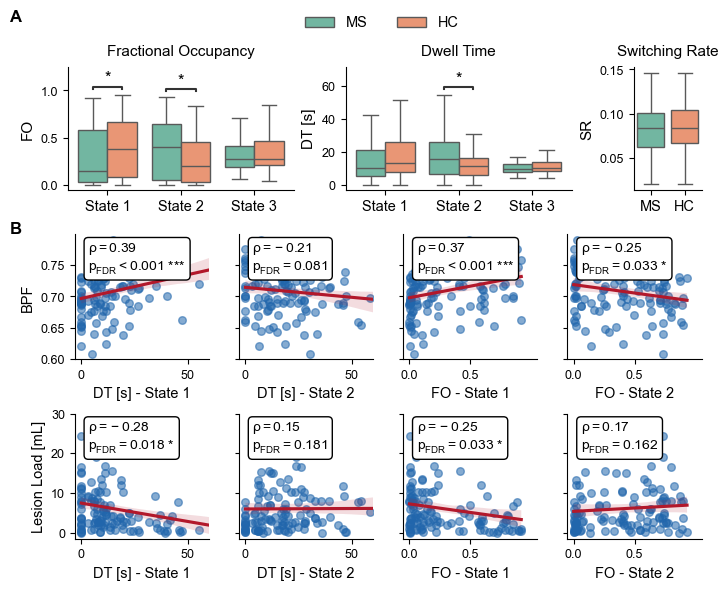

In [14]:
# Plot settings
scatter_color = "#2166ac"
line_color = "#b2182b"

previous_autolayout = plt.rcParams["figure.autolayout"]
plt.rcParams["figure.autolayout"] = False

# Figure layout
fig = plt.figure(figsize=(17.5/2.54, 14.2*(17.5/18)/2.54), constrained_layout=True)
outer_gs = gridspec.GridSpec(3, 1, figure=fig, height_ratios=[1, 0.07, 2])
gs_a = gridspec.GridSpecFromSubplotSpec(1, 3, subplot_spec=outer_gs[0], width_ratios=[1, 1, 0.3])

# Panel A: MS vs HC
for i, (metric, title) in enumerate(zip(metrics_a, titles_a)):
    ax = fig.add_subplot(gs_a[0, i])

    if metric != "SwitchRate":
        df_plot = df_hmm[df_hmm["State"].isin(states)].copy()

        sns.boxplot(data=df_plot, x="State", y=metric, hue="Group", order=states, hue_order=["MS", "HC"],
                    showfliers=False, palette="Set2", ax=ax)

        pairs = [((state, "MS"), (state, "HC")) for state in states]
        pvals = [group_stats[(metric, state)]["p_fdr"] for state in states]
        sigs = [group_stats[(metric, state)]["significant"] for state in states]

        pairs = [pair for pair, sig in zip(pairs, sigs) if sig]
        pvals = [p for p, sig in zip(pvals, sigs) if sig]

        if pairs:
            annot = Annotator(ax, pairs=pairs, data=df_plot, x="State", y=metric, hue="Group",
                              order=states, hue_order=["MS", "HC"])
            annot.configure(test=None, text_format="star", loc="inside", verbose=False,
                            pvalue_thresholds=[(0.001, "***"), (0.01, "**"), (0.05, "*"), (1, "")])
            annot.set_pvalues(pvals)
            annot.annotate()

        ax.get_legend().remove()

    else:
        sns.boxplot(data=df_sr, x="Group", y="SwitchRate", hue="Group", order=["MS", "HC"], hue_order=["MS", "HC"],
                    palette="Set2", legend=False, showfliers=False, ax=ax)

        if group_stats[("SwitchRate", None)]["significant"]:
            pval_sr = group_stats[("SwitchRate", None)]["p_fdr"]

            annot = Annotator(ax, pairs=[("MS", "HC")], data=df_sr, x="Group", y="SwitchRate",
                              order=["MS", "HC"])
            annot.configure(test=None, text_format="star", loc="inside", verbose=False,
                            pvalue_thresholds=[(0.001, "***"), (0.01, "**"), (0.05, "*"), (1, "")])
            annot.set_pvalues([pval_sr])
            annot.annotate()

    ax.set_title(title, fontsize=11.0, pad=8)
    ax.set_xlabel("")
    ax.set_ylabel(label_map_metrics.get(metric, metric), fontsize=11)
    ax.tick_params(axis="x", labelsize=10.5)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Global legend
handles, labels = fig.axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.53, 1.07),
           ncol=2, frameon=False, fontsize=10.5)

# Panel B: HMM-clinical correlations
nrows = len(clinical_vars_to_plot)
ncols = len(metrics_to_plot) * len(states_to_plot)
gs_b = gridspec.GridSpecFromSubplotSpec(nrows, ncols, subplot_spec=outer_gs[2], wspace=0.15)

for r, clin_var in enumerate(clinical_vars_to_plot):
    for m, metric in enumerate(metrics_to_plot):
        for s, state in enumerate(states_to_plot):
            c = m * len(states_to_plot) + s
            ax = fig.add_subplot(gs_b[r, c])

            df_state = df_merged[df_merged["State"] == state].copy()
            info = df_hmm_corr.query(
                "State == @state and HMM_metric == @metric and Clinical_var == @clin_var"
            )

            if info.empty:
                ax.axis("off")
                continue

            rho = float(info["Spearman_rho"].iloc[0])
            p_fdr = float(info["p_fdr"].iloc[0])

            sns.regplot(x=df_state[metric], y=df_state[clin_var], ax=ax,
                        scatter_kws={"s": 30, "alpha": 0.55, "color": scatter_color},
                        line_kws={"color": line_color})

            metric_label = label_map_metrics.get(metric, metric)
            ax.set_xlabel(f"{metric_label} - {state}", fontsize=10.5)

            if metric == "Dwell":
                ax.set_xticks([0, 50])
                ax.set_xlim(-3, 60)
            elif metric == "FO_soft":
                ax.set_xticks([0, 0.5])
                ax.set_xlim(-0.05, 1.05)

            if clin_var == "lesion_load":
                ax.set_ylim(-1.5, 30)
                ax.set_yticks([0, 10, 20, 30])

            if c == 0:
                ax.set_ylabel(label_map.get(clin_var, clin_var), fontsize=10.5)
            else:
                ax.set_ylabel("")
                ax.tick_params(axis="y", labelleft=False, length=3)

            textstr = r"$\rho = %.2f$" % rho + "\n" + p_text_fdr(p_fdr)
            ax.text(0.1, 0.95, textstr, transform=ax.transAxes, fontsize=10, va="top",
                    bbox=dict(facecolor="white", edgecolor="black", boxstyle="round,pad=0.3"))

            ax.spines["top"].set_visible(False)
            ax.spines["right"].set_visible(False)

# Panel labels
fig.text(-0.01, 1.03, "A", fontsize=12, fontweight="bold", ha="left", va="bottom")
fig.text(-0.01, 0.64, "B", fontsize=12, fontweight="bold", ha="left", va="bottom")

# Save
tif_path = FIG_DIR / "Fig3.tif"
fig.savefig(FIG_DIR / "Fig3.pdf", dpi=450, bbox_inches="tight")
fig.savefig(tif_path, format="tiff", dpi=450, bbox_inches="tight",facecolor="white", transparent=False, pil_kwargs={"compression": "tiff_lzw"})
convert_tiff_to_rgb(tif_path, print_check=False, fig=fig)

plt.show()
plt.rcParams["figure.autolayout"] = previous_autolayout

### Panel 4 

In [45]:
# Panel data
id_col = "participant_id"
cluster_col = "OT_cluster"

cluster_name_map = {0: "Severe", 1: "Mild"}
cluster_code_order = [0, 1]
cluster_order = [cluster_name_map[k] for k in cluster_code_order]

palette_values = sns.color_palette("Set2", n_colors=len(cluster_order))
palette_clusters = dict(zip(cluster_order, palette_values))

# OT results
C_dir = np.asarray(main["cost_matrix_dir"], float)
df_clusters = main["clusters_assignment"].copy()
df_cluster_stats = main["clusters_comparison"].copy()

df_meta = df_sel.copy()
df_meta.index = df_meta.index.astype(str)

subjects = df_meta.index.to_numpy()
groups = df_meta["group"].astype(str).str.strip().str.upper().to_numpy()
ms_mask = groups == "MS"
ms_idx = np.where(ms_mask)[0]
subjects_ms = subjects[ms_mask]

if C_dir.shape != (len(subjects), len(subjects)):
    raise ValueError("OT cost matrix and df_sel have incompatible subject dimensions.")

# Align cluster dataframe with MS subject order
df_clusters[id_col] = df_clusters[id_col].astype(str)
df_clusters = df_clusters.set_index(id_col).loc[subjects_ms].reset_index()
df_clusters[cluster_col] = df_clusters[cluster_col].astype(int)
df_clusters["ClusterName"] = df_clusters[cluster_col].map(cluster_name_map)

# Symmetric OT matrix and MDS embedding
C_sym = 0.5 * (C_dir + C_dir.T)
np.fill_diagonal(C_sym, 0.0)
C_sym_ms = C_sym[np.ix_(ms_idx, ms_idx)]

mds = MDS(n_components=2, dissimilarity="precomputed", random_state=41, n_init=10, max_iter=300)
embedding = mds.fit_transform(C_sym_ms)

df_clusters["OT_dim1"] = embedding[:, 0]
df_clusters["OT_dim2"] = embedding[:, 1]

# Directed MS cost matrix
C_dir_ms = C_dir[np.ix_(ms_idx, ms_idx)].copy()
np.fill_diagonal(C_dir_ms, 0.0)

cluster_rank = {code: rank for rank, code in enumerate(cluster_code_order)}
cluster_rank_values = np.asarray([cluster_rank[code] for code in df_clusters[cluster_col]])
order_plot = np.argsort(cluster_rank_values, kind="stable")

C_plot = C_dir_ms[np.ix_(order_plot, order_plot)]
clusters_plot = df_clusters["ClusterName"].to_numpy()[order_plot]

change_plot = np.flatnonzero(clusters_plot[:-1] != clusters_plot[1:]) + 1
codes_plot = pd.Categorical(clusters_plot, categories=cluster_order, ordered=True).codes
cmap_clusters = ListedColormap([palette_clusters[name] for name in cluster_order])

finite_costs = C_plot[np.isfinite(C_plot)]
cost_vmin = float(finite_costs.min())
cost_vmax = float(finite_costs.max())

# Clinical data
df_meta_reset = df_meta.reset_index()
ms_df = df_clusters.merge(df_meta_reset, on=id_col, how="left", validate="one_to_one")

feat_keys = ["EDSS", "SDMT", "BPF", "lesion_load"]
feat_label_map = {"EDSS": "EDSS", "SDMT": "SDMT", "BPF": "BPF", "lesion_load": "Lesion Load"}
feat_levels = [feat_label_map[feat] for feat in feat_keys]

p_lookup = df_cluster_stats.set_index("variable")["p_fdr_bh"].to_dict()
clinical_stars = {feat: significance_stars(float(p_lookup[feat])) for feat in feat_keys}

box_rows = []

for feat in feat_keys:
    d = ms_df[[id_col, "ClusterName", feat]].copy()
    d[feat] = pd.to_numeric(d[feat], errors="coerce")
    d = d.dropna(subset=[feat])

    feat_min = d[feat].min()
    feat_max = d[feat].max()

    d["Score"] = 0.0 if feat_max == feat_min else (d[feat] - feat_min) / (feat_max - feat_min)
    d["Feature"] = feat_label_map[feat]

    box_rows.append(d[[id_col, "ClusterName", "Feature", "Score"]])

df_clinical_plot = pd.concat(box_rows, ignore_index=True)

pairs_sig = []
stars_sig = []

for feat in feat_keys:
    if clinical_stars[feat]:
        pairs_sig.append(((feat_label_map[feat], cluster_order[0]),
                          (feat_label_map[feat], cluster_order[1])))
        stars_sig.append(clinical_stars[feat])

# Severe-Mild empirical FC difference
fcs_all_plot = np.asarray(fcs_all, float)

if len(fcs_all_plot) != len(df_meta):
    raise ValueError("fcs_all and df_sel have incompatible subject dimensions.")

df_fc = df_meta_reset[[id_col, "group"]].copy()
df_fc["fc_idx"] = np.arange(len(df_fc))

cluster_info = df_clusters[[id_col, cluster_col]].copy()
df_ms_clusters = df_fc.loc[ms_mask].merge(cluster_info, on=id_col, how="left", validate="one_to_one")

if df_ms_clusters[cluster_col].isna().any():
    missing_ids = df_ms_clusters.loc[df_ms_clusters[cluster_col].isna(), id_col].tolist()
    raise ValueError(f"Missing OT cluster labels for {len(missing_ids)} MS subjects: {missing_ids[:10]}")

df_ms_clusters[cluster_col] = df_ms_clusters[cluster_col].astype(int)

severe_idx = df_ms_clusters.loc[df_ms_clusters[cluster_col] == 0, "fc_idx"].to_numpy()
mild_idx = df_ms_clusters.loc[df_ms_clusters[cluster_col] == 1, "fc_idx"].to_numpy()

fc_mean_severe = fcs_all_plot[severe_idx].mean(axis=0)
fc_mean_mild = fcs_all_plot[mild_idx].mean(axis=0)
mean_fc_diff_severe_mild = fc_mean_severe - fc_mean_mild

# Seed-to-brain profiles
parcel_names_plot = np.asarray(parcel_names)
n_rois = mean_fc_diff_severe_mild.shape[0]

lh_dmn_temp_idx = get_parcel_idx(parcel_names_plot, include_all=["LH", "Default", "Temp"])
rh_dmn_temp_idx = get_parcel_idx(parcel_names_plot, include_all=["RH", "Default", "Temp"])
bil_dmn_temp_idx = np.concatenate([lh_dmn_temp_idx, rh_dmn_temp_idx])

lh_sommot_idx = get_parcel_idx(parcel_names_plot, include_all=["LH"], include_any=["SomMot"])
rh_sommot_idx = get_parcel_idx(parcel_names_plot, include_all=["RH"], include_any=["SomMot"])
bil_sommot_idx = np.concatenate([lh_sommot_idx, rh_sommot_idx])

if len(bil_dmn_temp_idx) == 0 or len(bil_sommot_idx) == 0:
    raise ValueError("DMN temporal or SomMot seed parcels were not found.")

dmn_temp_profile = mean_seed_profile(mean_fc_diff_severe_mild, bil_dmn_temp_idx, exclude_seed=True)
sommot_profile = mean_seed_profile(mean_fc_diff_severe_mild, bil_sommot_idx, exclude_seed=True)

dmn_temp_profile[bil_dmn_temp_idx] = np.nan
sommot_profile[bil_sommot_idx] = np.nan

profiles = [dmn_temp_profile, sommot_profile]

# Surface maps
surface_space = "conte69"
surface_titles = ["DMN Temporal", "SMN"]
surface_cmap = "RdBu_r"
surface_percentile = 99
surface_scale_mode = "separate"
surface_cbar_mode = "separate"
surface_cbar_orientation = "horizontal"

if surface_scale_mode == "shared":
    shared_surface_range = symmetric_percentile_range(
        np.concatenate([profile.ravel() for profile in profiles]),
        percentile=surface_percentile
    )
    surface_color_ranges = [shared_surface_range for _ in profiles]

elif surface_scale_mode == "separate":
    surface_color_ranges = [
        symmetric_percentile_range(profile, percentile=surface_percentile)
        for profile in profiles
    ]

else:
    raise ValueError("surface_scale_mode must be 'shared' or 'separate'.")

if surface_cbar_mode == "shared" and surface_scale_mode != "shared":
    raise ValueError("surface_cbar_mode='shared' requires surface_scale_mode='shared'.")

surfaces = fetch_fslr()
lh_surf, rh_surf = surfaces["veryinflated"]
lh_parc, rh_parc = load_parcellation("schaefer", scale=n_rois)

rendered_imgs = [
    render_surface_image(profile, n_parc=n_rois, lh_surf=lh_surf, rh_surf=rh_surf,
                         lh_parc=lh_parc, rh_parc=rh_parc, surface_space=surface_space,
                         cmap=surface_cmap, color_range=color_range, dpi=300)
    for profile, color_range in zip(profiles, surface_color_ranges)
]

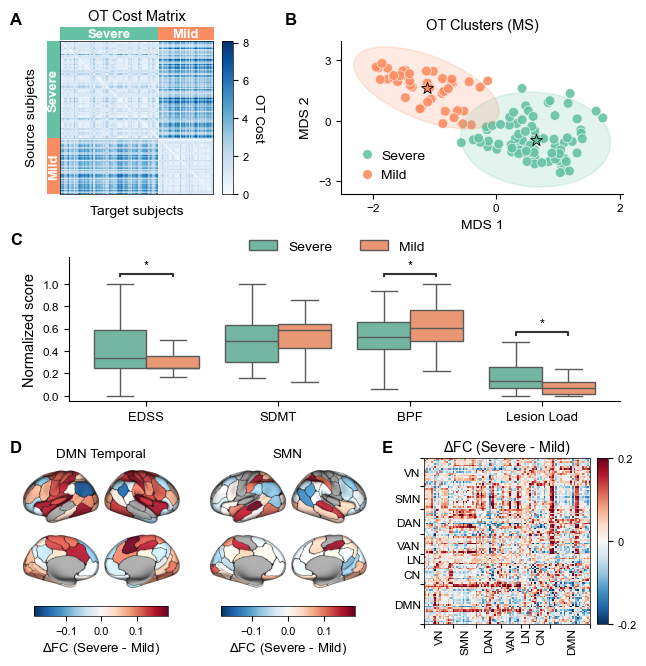

In [46]:
# Plot settings
cost_cmap = "Blues"
cost_title = "OT Cost Matrix"
cost_cbar_label = "OT Cost"

# Figure dimensions
figure_width_cm, figure_height_cm = 18.0, 16.5

# Scatter and ellipses
scatter_size, scatter_alpha = 50, 0.9
ellipse_alpha, ellipse_lw = 0.18, 1.2

# Layout spacing
gap_top_middle, gap_middle_bottom, gap_a_b = 0.35, 0.25, 0.30

# Panel positioning
panel_a_shift, panel_c_width, panel_c_shift = 0.03, 0.85, 0.07
panel_d_shift, panel_e_shift_x, panel_e_shift_y = 0.06, 0.012, 0.018

# Font sizes
title_fontsize, axis_label_fontsize, tick_fontsize = 10.5, 10.5, 8.5
legend_fontsize, panel_label_fontsize = 10.0, 12
cluster_strip_fontsize, matrix_network_label_size = 9.5, 1.90

surface_title_fontsize, matrix_title_fontsize = title_fontsize - 0.8, title_fontsize - 0.2
clinical_xtick_fontsize, significance_fontsize = tick_fontsize + 1, tick_fontsize + 0.5
cbar_label_fontsize, cbar_tick_fontsize = axis_label_fontsize - 1, tick_fontsize - 0.5

# Cluster strips
cluster_strip_thickness, cluster_strip_pad, cluster_label_pad = 0.083, 0.005, 0.05

# Colorbars
vertical_cbar_width, vertical_cbar_height = 0.015, 1
surface_cbar_height, surface_cbar_width_fraction = 0.015, 0.80

surface_cbar_label = fr"$\Delta$FC ({cluster_name_map[0]} - {cluster_name_map[1]})"
matrix_difference_title = fr"$\Delta$FC ({cluster_name_map[0]} - {cluster_name_map[1]})"
matrix_difference_vmax = 0.2
matrix_difference_cmap = "RdBu_r"

c_left_space = (1 - panel_c_width) / 2 + panel_c_shift
c_right_space = (1 - panel_c_width) / 2 - panel_c_shift

previous_autolayout = plt.rcParams["figure.autolayout"]
plt.rcParams["figure.autolayout"] = False

# Figure layout
fig = plt.figure(figsize=(figure_width_cm / 2.54, figure_height_cm / 2.54), constrained_layout=False)

outer_gs = gridspec.GridSpec(5, 1, figure=fig, height_ratios=[0.85, gap_top_middle, 0.80, gap_middle_bottom, 0.92], hspace=0)
top_gs = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=outer_gs[0], width_ratios=[1, 1], wspace=gap_a_b)
middle_gs = gridspec.GridSpecFromSubplotSpec(1, 3, subplot_spec=outer_gs[2], width_ratios=[c_left_space, panel_c_width, c_right_space], wspace=0)
bottom_outer_gs = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=outer_gs[4], width_ratios=[2.0, 1.4], wspace=0.15)
surface_gs = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=bottom_outer_gs[0, 0], width_ratios=[1, 1], wspace=0.11)

ax_a = fig.add_subplot(top_gs[0, 0])
ax_b = fig.add_subplot(top_gs[0, 1])
ax_c = fig.add_subplot(middle_gs[0, 1])
ax_d_dmn = fig.add_subplot(surface_gs[0, 0])
ax_d_smn = fig.add_subplot(surface_gs[0, 1])
ax_e = fig.add_subplot(bottom_outer_gs[0, 1])

fig.subplots_adjust(left=0.05, right=0.965, bottom=0.080, top=0.960)

pos_a_base = ax_a.get_position()
ax_a.set_position([pos_a_base.x0 + panel_a_shift, pos_a_base.y0, pos_a_base.width, pos_a_base.height])  # type:ignore

for ax in [ax_d_dmn, ax_d_smn]:
    pos_d = ax.get_position()
    ax.set_position([pos_d.x0 + panel_d_shift, pos_d.y0, pos_d.width, pos_d.height])  # type:ignore

pos_e_base = ax_e.get_position()
ax_e.set_position([pos_e_base.x0 + panel_e_shift_x, pos_e_base.y0 - panel_e_shift_y, pos_e_base.width, pos_e_base.height])  # type:ignore

# Panel A: directed OT cost matrix
im_a = ax_a.imshow(C_plot, cmap=cost_cmap, vmin=cost_vmin, vmax=cost_vmax)

for boundary in change_plot:
    ax_a.axhline(boundary - 0.5, color="white", lw=0.5)
    ax_a.axvline(boundary - 0.5, color="white", lw=0.5)

ax_a.set_title(cost_title, fontsize=title_fontsize, pad=5)
ax_a.set_xlabel("Target subjects", fontsize=axis_label_fontsize - 0.5, labelpad=8)
ax_a.set_ylabel("Source subjects", fontsize=axis_label_fontsize - 0.5, labelpad=16)
ax_a.set_xticks([])
ax_a.set_yticks([])

for spine_name in ax_a.spines:
    ax_a.spines[spine_name].set_visible(True)
    ax_a.spines[spine_name].set_edgecolor("black")
    ax_a.spines[spine_name].set_linewidth(0.5)

ax_top = ax_a.inset_axes([0, 1 + cluster_strip_pad, 1, cluster_strip_thickness])  # type:ignore
ax_top.set_in_layout(False)
ax_top.imshow(codes_plot[np.newaxis, :], aspect="auto", cmap=cmap_clusters, vmin=0, vmax=1)
ax_top.axis("off")

ax_left = ax_a.inset_axes([-(cluster_strip_thickness + cluster_strip_pad), 0, cluster_strip_thickness, 1])  # type:ignore
ax_left.set_in_layout(False)
ax_left.imshow(codes_plot[:, np.newaxis], aspect="auto", cmap=cmap_clusters, vmin=0, vmax=1)
ax_left.axis("off")

for cluster_name in cluster_order:
    idx = np.where(clusters_plot == cluster_name)[0]

    if idx.size:
        midpoint = 0.5 * (idx[0] + idx[-1]) 

        ax_top.text(midpoint, cluster_label_pad, cluster_name, ha="center", va="center", color="white",
                    fontsize=cluster_strip_fontsize, fontweight="semibold")
        ax_left.text(cluster_label_pad, midpoint, cluster_name, ha="center", va="center", color="white",
                     fontsize=cluster_strip_fontsize, fontweight="semibold", rotation=90)

# Panel B: MDS embedding
sns.scatterplot(data=df_clusters, x="OT_dim1", y="OT_dim2", hue="ClusterName", hue_order=cluster_order,
                palette=palette_clusters, edgecolor="white", linewidth=0.6, s=scatter_size, alpha=scatter_alpha, ax=ax_b)

for cluster_name in cluster_order:
    d = df_clusters.loc[df_clusters["ClusterName"] == cluster_name]

    if len(d) >= 3:
        add_cov_ellipse(ax_b, d["OT_dim1"].to_numpy(), d["OT_dim2"].to_numpy(),
                        palette_clusters[cluster_name], alpha=ellipse_alpha, lw=ellipse_lw)

ax_b.set_title("OT Clusters (MS)", fontsize=title_fontsize, pad=8)
ax_b.set_xlabel("MDS 1", fontsize=axis_label_fontsize - 0.5)
ax_b.set_ylabel("MDS 2", fontsize=axis_label_fontsize - 0.5)
ax_b.set_yticks([-3, 0, 3])
ax_b.set_xticks([-2, 0, 2])
ax_b.tick_params(axis="both", labelsize=tick_fontsize)
ax_b.legend(frameon=False, loc="lower left", title=None, handletextpad=0, fontsize=legend_fontsize)
ax_b.spines["top"].set_visible(False)
ax_b.spines["right"].set_visible(False)

# Panel C: clinical variables
sns.boxplot(data=df_clinical_plot, x="Feature", y="Score", hue="ClusterName", hue_order=cluster_order,
            order=feat_levels, palette=palette_clusters, showfliers=False, ax=ax_c)

handles, labels = ax_c.get_legend_handles_labels()

if ax_c.get_legend() is not None:
    ax_c.get_legend().remove()

if pairs_sig:
    annot = Annotator(ax_c, pairs=pairs_sig, data=df_clinical_plot, x="Feature", y="Score",
                      hue="ClusterName", order=feat_levels, hue_order=cluster_order)
    annot.configure(test=None, loc="inside", verbose=False, fontsize=significance_fontsize)
    annot.set_custom_annotations(stars_sig)
    annot.annotate()

ax_c.set_xlabel("")
ax_c.set_ylabel("Normalized score", fontsize=axis_label_fontsize)
ax_c.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1])
ax_c.set_xticks(np.arange(len(feat_levels)))
ax_c.set_xticklabels(feat_levels, fontsize=clinical_xtick_fontsize)
ax_c.tick_params(axis="y", labelsize=tick_fontsize)
ax_c.spines["top"].set_visible(False)
ax_c.spines["right"].set_visible(False)

# Panel D: surface maps
surface_axes = [ax_d_dmn, ax_d_smn]

for ax, img, title in zip(surface_axes, rendered_imgs, surface_titles):
    ax.imshow(img)
    ax.axis("off")
    ax.set_title(title, fontsize=surface_title_fontsize, pad=3)

# Panel E: whole-brain FC difference
plot_matrices([mean_fc_diff_severe_mild], network_labels=network_labels, network_names=network_names, titles=[matrix_difference_title],
              vminvmax=[[-matrix_difference_vmax, matrix_difference_vmax]], center=0, cmap=matrix_difference_cmap,
              label_pad_x=2.15, label_pad_y=2.15, x_label_shift=0.82, y_label_shift=0.82,
              label_size=matrix_network_label_size, figsize_per_matrix=(4.5, 3.3), sort=True, axes=ax_e, cbar=False)

ax_e.set_title(matrix_difference_title, fontsize=matrix_title_fontsize, pad=5)
ax_e.tick_params(axis="both", labelsize=tick_fontsize)

# Manual colorbars
fig.canvas.draw()

pos_a = ax_a.get_position()
cbar_height_a = pos_a.height * vertical_cbar_height

cax_a = fig.add_axes([pos_a.x1 + 0.012, pos_a.y0 + (pos_a.height - cbar_height_a) / 2, vertical_cbar_width, cbar_height_a])  # type:ignore

cbar_a = fig.colorbar(im_a, cax=cax_a)
cbar_a.set_label(cost_cbar_label, rotation=270, labelpad=11, fontsize=cbar_label_fontsize)
cbar_a.outline.set_edgecolor("black")  # type: ignore
cbar_a.outline.set_linewidth(0.5)  # type: ignore
cbar_a.ax.tick_params(labelsize=cbar_tick_fontsize)

add_surface_colorbars(fig, surface_axes, surface_color_ranges, cmap=surface_cmap, mode=surface_cbar_mode,
                      orientation=surface_cbar_orientation, pad=0.014, thickness=surface_cbar_height,
                      length=surface_cbar_width_fraction, label=surface_cbar_label,
                      ticksize=cbar_tick_fontsize, labelsize=cbar_label_fontsize)  # type:ignore

fig.canvas.draw()

pos_e = ax_e.get_position()
cbar_height_e = pos_e.height * vertical_cbar_height

if len(ax_e.collections) > 0:
    matrix_mappable = ax_e.collections[0]
elif len(ax_e.images) > 0:
    matrix_mappable = ax_e.images[0]
else:
    raise RuntimeError("No mappable object was found in panel E.")

cax_e = fig.add_axes([pos_e.x1 + 0.010, pos_e.y0 + (pos_e.height - cbar_height_e) / 2, vertical_cbar_width, cbar_height_e])  # type:ignore

cbar_e = fig.colorbar(matrix_mappable, cax=cax_e)
cbar_e.set_ticks([-matrix_difference_vmax, 0, matrix_difference_vmax])
cbar_e.set_ticklabels([f"{-matrix_difference_vmax:.1f}", "0", f"{matrix_difference_vmax:.1f}"])
cbar_e.outline.set_edgecolor("black")  # type: ignore
cbar_e.outline.set_linewidth(0.5)  # type: ignore
cbar_e.ax.tick_params(labelsize=cbar_tick_fontsize)

# Clinical legend
fig.canvas.draw()

pos_c = ax_c.get_position()
clinical_legend_x = pos_c.x0 + pos_c.width / 2

fig.legend(handles[:len(cluster_order)], labels[:len(cluster_order)], loc="upper center",
           bbox_to_anchor=(clinical_legend_x - 0.01, pos_c.y1 + 0.045), ncol=len(cluster_order),
           frameon=False, fontsize=legend_fontsize)

# Panel labels
fig.canvas.draw()

pos_a = ax_a.get_position()
pos_b = ax_b.get_position()
pos_c = ax_c.get_position()
pos_d_dmn = ax_d_dmn.get_position()
pos_d_smn = ax_d_smn.get_position()
pos_e = ax_e.get_position()

x_left_labels = min(pos_a.x0, pos_c.x0, pos_d_dmn.x0) - 0.01
x_b_label = pos_b.x0 - 0.08
x_e_label = pos_e.x0 - 0.06

y_top_labels = max(pos_a.y1, pos_b.y1) + 0.02
y_middle_labels = pos_c.y1 + 0.015
y_bottom_labels = max(pos_d_dmn.y1, pos_d_smn.y1, pos_e.y1) + 0.005

fig.text(x_left_labels, y_top_labels, "A", fontsize=panel_label_fontsize, fontweight="bold", ha="left", va="bottom")
fig.text(x_b_label, y_top_labels, "B", fontsize=panel_label_fontsize, fontweight="bold", ha="left", va="bottom")
fig.text(x_left_labels, y_middle_labels, "C", fontsize=panel_label_fontsize, fontweight="bold", ha="left", va="bottom")
fig.text(x_left_labels, y_bottom_labels, "D", fontsize=panel_label_fontsize, fontweight="bold", ha="left", va="bottom")
fig.text(x_e_label, y_bottom_labels, "E", fontsize=panel_label_fontsize, fontweight="bold", ha="left", va="bottom")

# Save
tif_path = FIG_DIR / "Fig4.tif"
fig.savefig(FIG_DIR / "Fig4.pdf", dpi=450, bbox_inches="tight")
fig.savefig(tif_path, format="tiff", dpi=450, bbox_inches="tight", facecolor="white", transparent=False, pil_kwargs={"compression": "tiff_lzw"})
convert_tiff_to_rgb(tif_path, print_check=False, fig=fig)

plt.show()
plt.rcParams["figure.autolayout"] = previous_autolayout

## Supplementary Panels

### Model Selection

In [48]:
# Panel data
explained_variance_ratio = np.load(DATA_DIR / "pca_explained_variance_ratio.npy")
df_cv_zeromean = main["hmm_crossval_zeromean"].copy()

n_splits = 5
selected_M = 30

df_cv_summary = (
    df_cv_zeromean.groupby(["n_components", "n_states"], as_index=False)
    .agg(mean_ll_val_per_subject=("ll_val_per_subject", "mean"), sd_ll_val_per_subject=("ll_val_per_subject", "std"))
)
df_cv_summary["se_ll_val_per_subject"] = df_cv_summary["sd_ll_val_per_subject"] / np.sqrt(n_splits)

m_values = np.sort(df_cv_summary["n_components"].unique())
n_m = len(m_values)
ncols_cv = min(3, n_m)
nrows_cv = int(np.ceil(n_m / ncols_cv))

pc_idx = np.arange(1, len(explained_variance_ratio) + 1)
cum_explained = np.cumsum(explained_variance_ratio)
selected_cum_explained = cum_explained[selected_M - 1]
pc_ticks = np.unique(np.linspace(1, len(pc_idx), min(6, len(pc_idx)), dtype=int))

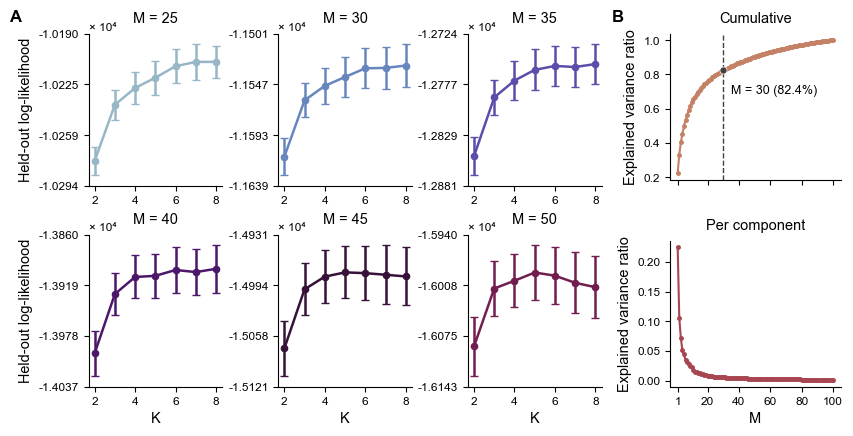

In [49]:
# Plot settings
figure_width_cm, figure_height_cm = 21.0, 11.5

# Font sizes
title_fontsize, axis_label_fontsize, tick_fontsize = 10.5, 10.5, 8.5
panel_label_fontsize = 12

# Layout spacing
outer_wspace, cv_wspace, cv_hspace = 0.2, 0.42, 0.32

# Colors
twilight_vals = np.linspace(0.12, 0.82, max(n_m + 2, 4))
twilight_colors = plt.cm.twilight(twilight_vals)  # type: ignore
cv_colors = twilight_colors[:n_m]
cum_color, component_color = twilight_colors[-1], twilight_colors[-2]

previous_autolayout = plt.rcParams["figure.autolayout"]
plt.rcParams["figure.autolayout"] = False

# Figure layout
fig = plt.figure(figsize=(figure_width_cm / 2.54, figure_height_cm / 2.54), constrained_layout=False)
outer_gs = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[3.0, 1.0], wspace=outer_wspace)
cv_gs = gridspec.GridSpecFromSubplotSpec(nrows_cv, ncols_cv, subplot_spec=outer_gs[0], wspace=cv_wspace, hspace=cv_hspace)
variance_gs = gridspec.GridSpecFromSubplotSpec(2, 1, subplot_spec=outer_gs[1], hspace=0.42)

axes_cv = [fig.add_subplot(cv_gs[i // ncols_cv, i % ncols_cv]) for i in range(nrows_cv * ncols_cv)]
ax_cum = fig.add_subplot(variance_gs[0])
ax_component = fig.add_subplot(variance_gs[1])

fig.subplots_adjust(left=0.075, right=0.985, bottom=0.14, top=0.92)

# Panel A: cross-validation
for i, M in enumerate(m_values):
    ax = axes_cv[i]
    row = i // ncols_cv
    d_plot = df_cv_summary[df_cv_summary["n_components"] == M].sort_values("n_states")

    ax.errorbar(d_plot["n_states"], d_plot["mean_ll_val_per_subject"], yerr=d_plot["se_ll_val_per_subject"],
                marker="o", markersize=4.5, linewidth=1.8, capsize=3, color=cv_colors[i])

    ax.set_title(f"M = {int(M)}", fontsize=title_fontsize, pad=8)
    ax.set_xlabel("K" if row == nrows_cv - 1 else "", fontsize=axis_label_fontsize)
    ax.set_ylabel("Held-out log-likelihood" if i % ncols_cv == 0 else "", fontsize=axis_label_fontsize)

    y_low = np.min(d_plot["mean_ll_val_per_subject"] - d_plot["se_ll_val_per_subject"])
    y_high = np.max(d_plot["mean_ll_val_per_subject"] + d_plot["se_ll_val_per_subject"])
    y_pad = 0.08 * (y_high - y_low)
    if y_pad == 0:
        y_pad = max(abs(y_low), 1.0) * 0.01

    ax.set_ylim(y_low - y_pad, y_high + y_pad)
    ax.yaxis.set_major_locator(LinearLocator(4))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y / 1e4:.4f}"))
    ax.text(0.0, 1.01, "× 10⁴", transform=ax.transAxes, fontsize=tick_fontsize, ha="left", va="bottom")

    ax.set_xticks([2, 4, 6, 8])
    ax.tick_params(axis="both", labelsize=tick_fontsize)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

for j in range(n_m, len(axes_cv)):
    axes_cv[j].axis("off")

# Panel B: cumulative explained variance
ax_cum.plot(pc_idx, cum_explained, "o-", color=cum_color, linewidth=1.5, markersize=2.5)
ax_cum.axvline(selected_M, color="0.25", linestyle="--", linewidth=1.0)
ax_cum.scatter(selected_M, selected_cum_explained, s=26, color="0.25", edgecolor="white", linewidth=0.5, zorder=5)
ax_cum.annotate(f"M = {selected_M} ({100 * selected_cum_explained:.1f}%)",
                xy=(selected_M, selected_cum_explained), xytext=(selected_M + 5, selected_cum_explained - 0.08),
                fontsize=9, ha="left", va="top")

ax_cum.set_title("Cumulative", fontsize=title_fontsize, pad=8)
ax_cum.set_ylabel("Explained variance ratio", fontsize=axis_label_fontsize)
ax_cum.set_xticks(pc_ticks)
ax_cum.set_xticklabels([])
ax_cum.tick_params(axis="both", labelsize=tick_fontsize)
ax_cum.spines["top"].set_visible(False)
ax_cum.spines["right"].set_visible(False)

# Panel B: per-component explained variance
ax_component.plot(pc_idx, explained_variance_ratio, "o-", color=component_color, linewidth=1.5, markersize=2.5)
ax_component.set_title("Per component", fontsize=title_fontsize, pad=8)
ax_component.set_xlabel("M", fontsize=axis_label_fontsize)
ax_component.set_ylabel("Explained variance ratio", fontsize=axis_label_fontsize)
ax_component.set_xticks(pc_ticks)
ax_component.tick_params(axis="both", labelsize=tick_fontsize)
ax_component.spines["top"].set_visible(False)
ax_component.spines["right"].set_visible(False)

# Panel labels
fig.canvas.draw()
pos_a = axes_cv[0].get_position()
pos_b = ax_cum.get_position()

fig.text(pos_a.x0 - 0.095, pos_a.y1 + 0.02, "A", fontsize=panel_label_fontsize, fontweight="bold", ha="left", va="bottom")
fig.text(pos_b.x0 - 0.07, pos_b.y1 + 0.02, "B", fontsize=panel_label_fontsize, fontweight="bold", ha="left", va="bottom")

# Save
tif_path = FIG_DIR / "SI_FigA.tif"
fig.savefig(FIG_DIR / "SI_FigA.pdf", dpi=450, bbox_inches="tight")
fig.savefig(tif_path, format="tiff", dpi=450, bbox_inches="tight", facecolor="white", transparent=False, pil_kwargs={"compression": "tiff_lzw"})
convert_tiff_to_rgb(tif_path, print_check=False, fig=fig)

plt.show()
plt.rcParams["figure.autolayout"] = previous_autolayout

### FC HC-MS differences

In [30]:
def run_welch_edges(group1_edges, group2_edges, alpha=0.05):
    '''
    Run edge-wise Welch t-tests with FDR correction.
    '''
    _, p_vals = ttest_ind(group1_edges, group2_edges, axis=0, equal_var=False, nan_policy="omit")

    finite = np.isfinite(p_vals)  # type: ignore
    p_fdr = np.full_like(p_vals, np.nan, dtype=float)
    reject = np.zeros_like(p_vals, dtype=bool)
    reject[finite], p_fdr[finite], _, _ = multipletests(p_vals[finite], alpha=alpha, method="fdr_bh")  # type: ignore

    return p_vals, p_fdr, reject

In [31]:
# Group FC matrices
fcs_hc = np.asarray(fcs_all[hc_mask], float)
fcs_ms = np.asarray(fcs_all[ms_mask], float)

fc_mean_hc = fcs_hc.mean(axis=0)
fc_mean_ms = fcs_ms.mean(axis=0)
fc_diff_ms_hc = fc_mean_ms - fc_mean_hc

# Edge-wise inference
eps_fc = 1e-7
iu_fc = np.triu_indices(fcs_all.shape[1], k=1)

hc_edges_z = np.arctanh(np.clip(fcs_hc[:, iu_fc[0], iu_fc[1]], -1 + eps_fc, 1 - eps_fc))
ms_edges_z = np.arctanh(np.clip(fcs_ms[:, iu_fc[0], iu_fc[1]], -1 + eps_fc, 1 - eps_fc))

p_edges, p_edges_fdr, sig_edges_fdr = run_welch_edges(ms_edges_z, hc_edges_z)
sig_edges_unc = np.isfinite(p_edges) & (p_edges < 0.05)  # type: ignore

print(f"Max |MS - HC| FC difference: {np.max(np.abs(fc_diff_ms_hc)):.4f}")
print(f"Uncorrected significant edges: {sig_edges_unc.sum()}/{len(p_edges)}")  # type: ignore
print(f"FDR-significant edges: {sig_edges_fdr.sum()}/{len(p_edges)}")  # type: ignore

Max |MS - HC| FC difference: 0.1514
Uncorrected significant edges: 364/4950
FDR-significant edges: 0/4950


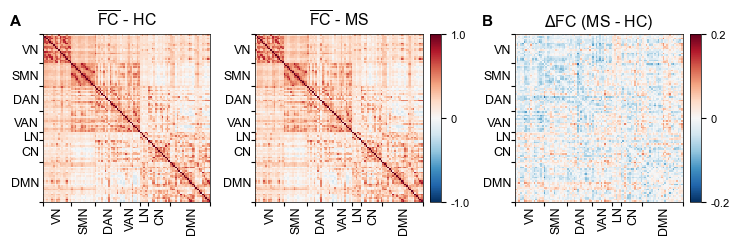

In [32]:
# Figure settings
fc_vmin, fc_vmax = -1.0, 1.0
diff_vmax = 0.2
fc_titles = [r"$\overline{\mathrm{FC}}$ - HC", r"$\overline{\mathrm{FC}}$ - MS"]
diff_title = r"$\Delta$FC (MS - HC)"

figure_width_cm_fcgroup, figure_height_cm_fcgroup = 18.5, 5.6
title_fontsize_fcgroup, tick_fontsize_fcgroup = 11.5, 8.0
panel_label_fontsize_fcgroup = 11.0

fig_fcgroup = plt.figure(figsize=(figure_width_cm_fcgroup / 2.54, figure_height_cm_fcgroup / 2.54))
outer_gs_fcgroup = gridspec.GridSpec(1, 2, figure=fig_fcgroup, width_ratios=[2.10, 1.00], wspace=0.25)
gs_a_fcgroup = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=outer_gs_fcgroup[0], wspace=0.15)

axes_fcgroup = [fig_fcgroup.add_subplot(gs_a_fcgroup[0, i]) for i in range(2)]
ax_diff_fcgroup = fig_fcgroup.add_subplot(outer_gs_fcgroup[1])
fig_fcgroup.subplots_adjust(left=0.035, right=0.94, bottom=0.12, top=0.88)

# Group-average FC
plot_matrices(
    [fc_mean_hc, fc_mean_ms], network_labels=network_labels, network_names=network_names,
    titles=fc_titles, vminvmax=[[fc_vmin, fc_vmax]] * 2, center=0, cmap="RdBu_r",
    figsize_per_matrix=(3.0, 3.0), sort=True, labels_for=[0, 1],
    label_pad_x=2.2, label_pad_y=2.2, label_size=3.0,
    x_label_shift=0.82, y_label_shift=0.82, axes=axes_fcgroup, cbar=False
)

for ax, title in zip(axes_fcgroup, fc_titles):
    ax.set_title(title, fontsize=title_fontsize_fcgroup, pad=6)

# MS - HC difference
plot_matrices([fc_diff_ms_hc], network_labels=network_labels, network_names=network_names, titles=[diff_title], 
              vminvmax=[[-diff_vmax, diff_vmax]], center=0, cmap="RdBu_r", figsize_per_matrix=(3.0, 3.0), sort=True, 
              labels_for=[0], label_pad_x=2.2, label_pad_y=2.2, label_size=3.0, x_label_shift=0.82, y_label_shift=0.82, 
              axes=ax_diff_fcgroup, cbar=False)
ax_diff_fcgroup.set_title(diff_title, fontsize=title_fontsize_fcgroup, pad=6)

# Colorbars
fig_fcgroup.canvas.draw()
pos_fcgroup = axes_fcgroup[-1].get_position()
pos_diff_fcgroup = ax_diff_fcgroup.get_position()

cax_fcgroup = fig_fcgroup.add_axes([pos_fcgroup.x1 + 0.01, pos_fcgroup.y0, 0.015, pos_fcgroup.height])  # type: ignore
cbar_fcgroup = fig_fcgroup.colorbar(axes_fcgroup[0].collections[0], cax=cax_fcgroup)
cbar_fcgroup.set_ticks([fc_vmin, 0, fc_vmax])
cbar_fcgroup.set_ticklabels([f"{fc_vmin:.1f}", "0", f"{fc_vmax:.1f}"])
cbar_fcgroup.ax.tick_params(labelsize=tick_fontsize_fcgroup)
cbar_fcgroup.outline.set_edgecolor("black")  # type: ignore
cbar_fcgroup.outline.set_linewidth(0.5)  # type: ignore

cax_diff_fcgroup = fig_fcgroup.add_axes([pos_diff_fcgroup.x1 + 0.01, pos_diff_fcgroup.y0, 0.015, pos_diff_fcgroup.height])  # type: ignore
cbar_diff_fcgroup = fig_fcgroup.colorbar(ax_diff_fcgroup.collections[0], cax=cax_diff_fcgroup)
cbar_diff_fcgroup.set_ticks([-diff_vmax, 0, diff_vmax])
cbar_diff_fcgroup.set_ticklabels([f"{-diff_vmax:.1f}", "0", f"{diff_vmax:.1f}"])
cbar_diff_fcgroup.ax.tick_params(labelsize=tick_fontsize_fcgroup)
cbar_diff_fcgroup.outline.set_edgecolor("black")  # type: ignore
cbar_diff_fcgroup.outline.set_linewidth(0.5)  # type: ignore

# Panel labels
fig_fcgroup.canvas.draw()
pos_a_fcgroup = axes_fcgroup[0].get_position()
pos_b_fcgroup = ax_diff_fcgroup.get_position()
panel_y_fcgroup = max(pos_a_fcgroup.y1, pos_b_fcgroup.y1) + 0.03

fig_fcgroup.text(pos_a_fcgroup.x0 - 0.045, panel_y_fcgroup, "A",
                 fontsize=panel_label_fontsize_fcgroup, fontweight="bold", ha="left", va="bottom")
fig_fcgroup.text(pos_b_fcgroup.x0 - 0.045, panel_y_fcgroup, "B",
                 fontsize=panel_label_fontsize_fcgroup, fontweight="bold", ha="left", va="bottom")

# Save
tif_path = FIG_DIR / "SI_FigB.tif"
fig_fcgroup.savefig(FIG_DIR / "SI_FigB.pdf", dpi=450, bbox_inches="tight")
fig_fcgroup.savefig(tif_path, format="tiff", dpi=450, bbox_inches="tight", facecolor="white", transparent=False, pil_kwargs={"compression": "tiff_lzw"})
convert_tiff_to_rgb(tif_path, print_check=False, fig=fig_fcgroup)

plt.show()

### Clustering robustness analysis

In [50]:
def symmetrize(A, mode="mean"):
    '''
    Symmetrize a matrix using the mean, maximum, or minimum rule.
    '''
    A = np.asarray(A, float)
    if mode == "mean":
        S = 0.5 * (A + A.T)
    elif mode == "max":
        S = np.maximum(A, A.T)
    elif mode == "min":
        S = np.minimum(A, A.T)
    else:
        raise ValueError("mode must be one of: 'mean', 'max', 'min'")
    np.fill_diagonal(S, 0.0)
    return S


def symmetry_degree(A):
    '''
    Compute a simple degree of symmetry based on matrix norms.
    '''
    A = np.asarray(A, float)
    diff = np.linalg.norm(A - A.T)
    tot = np.linalg.norm(A)
    return 1.0 if tot == 0 else 1.0 - diff / tot


def upper_flat(A):
    '''
    Return the upper-triangular part of a square matrix as a vector.
    '''
    iu = np.triu_indices_from(A, k=1)
    return A[iu]


def knn_sets(D, k=5):
    '''
    Return the set of k nearest neighbours for each row of a distance matrix.
    '''
    out = []
    for i in range(D.shape[0]):
        idx = np.argsort(D[i])
        out.append(set(idx[1:k + 1]))
    return out


def inter_cluster_mean_distance(D, labels):
    '''
    Compute the mean distance between two clusters.
    '''
    labs = np.unique(labels)
    if len(labs) < 2:
        return np.nan
    i0 = np.where(labels == labs[0])[0]
    i1 = np.where(labels == labs[1])[0]
    return float(D[np.ix_(i0, i1)].mean())


def align_labels_to_reference(labels, reference):
    '''
    Align cluster labels to a reference labeling via maximum overlap.
    '''
    labels = np.asarray(labels, int)
    reference = np.asarray(reference, int)

    contingency = pd.crosstab(pd.Series(labels, name="labels"), pd.Series(reference, name="reference"))
    row_idx, col_idx = linear_sum_assignment(-contingency.to_numpy())
    mapping = {contingency.index[i]: contingency.columns[j] for i, j in zip(row_idx, col_idx)}

    return np.asarray([mapping[label] for label in labels], dtype=int)

In [51]:
# Symmetrization settings
sym_modes, sym_k_range = ["mean", "max", "min"], range(2, 5)
sym_linkage, nn_k = "average", 5
mds_seed, mds_n_init, mds_max_iter = 41, 10, 300
mode_title_map = {"mean": "Mean", "max": "Maximum", "min": "Minimum"}

# OT results
C_dir = np.asarray(main["cost_matrix_dir"], float).copy()

subjects = df_sel.index.astype(str).to_numpy()
groups = df_sel["group"].astype(str).str.strip().str.upper().to_numpy()  # type: ignore
ms_mask = groups == "MS"
ms_idx = np.where(ms_mask)[0]
subjects_ms = subjects[ms_mask]

if C_dir.shape != (len(subjects), len(subjects)):
    raise ValueError("OT cost matrix and df_sel have incompatible subject dimensions.")

np.fill_diagonal(C_dir, 0.0)
C_dir_ms = C_dir[np.ix_(ms_idx, ms_idx)]
ms_df_base = pd.DataFrame({"participant_id": subjects_ms})

# Clustering, silhouette and MDS
sym_rows, sym_results = [], {}

for mode in sym_modes:
    C_ms_mode = symmetrize(C_dir_ms, mode=mode)
    best_mode = {"k": None, "silhouette": -np.inf, "labels": None}

    for k in sym_k_range:
        labels_mode = AgglomerativeClustering(n_clusters=k, metric="precomputed", linkage=sym_linkage).fit_predict(C_ms_mode)
        silhouette_mode = silhouette_score(C_ms_mode, labels_mode, metric="precomputed")
        sym_rows.append({"mode": mode, "k": k, "silhouette": silhouette_mode})

        if silhouette_mode > best_mode["silhouette"]:
            best_mode = {"k": int(k), "silhouette": float(silhouette_mode), "labels": labels_mode.copy()}

    embedding_mode = MDS(n_components=2, dissimilarity="precomputed", random_state=mds_seed,
                         n_init=mds_n_init, max_iter=mds_max_iter).fit_transform(C_ms_mode)

    ms_df_mode = ms_df_base.copy()
    ms_df_mode["OT_cluster"] = np.asarray(best_mode["labels"], int)
    ms_df_mode["OT_dim1"] = embedding_mode[:, 0]
    ms_df_mode["OT_dim2"] = embedding_mode[:, 1]

    sym_results[mode] = {"C_ms": C_ms_mode, "best": best_mode, "ms_df": ms_df_mode}

df_sil_sym = pd.DataFrame(sym_rows).sort_values(["mode", "k"]).reset_index(drop=True)

# Reference clustering
ref_k_sym = int(sym_results["mean"]["best"]["k"])
ref_labels_sym = np.asarray(sym_results["mean"]["best"]["labels"], int)

for mode in sym_modes:
    best_mode = sym_results[mode]["best"]
    labels_mode = np.asarray(best_mode["labels"], int)
    labels_plot_mode = align_labels_to_reference(labels_mode, ref_labels_sym) if int(best_mode["k"]) == ref_k_sym else labels_mode
    sym_results[mode]["ms_df"]["OT_cluster_plot"] = labels_plot_mode

# Silhouette summary
print("Silhouette and k selection")

for mode in sym_modes:
    d_print = df_sil_sym[df_sil_sym["mode"] == mode]
    line_print = ", ".join(f"k={row.k} sil={row.silhouette:.4f}" for row in d_print.itertuples(index=False))
    print(f"Mode {mode:<4}: {line_print}")

print(f"\nBest k (mean) = {ref_k_sym} (sil={sym_results['mean']['best']['silhouette']:.4f})")

# Cluster agreement at reference k
print(f"\nCluster agreement vs mean using k = {ref_k_sym}")

for mode in ["max", "min"]:
    C_ms_mode = sym_results[mode]["C_ms"]
    labels_mode = AgglomerativeClustering(n_clusters=ref_k_sym, metric="precomputed", linkage=sym_linkage).fit_predict(C_ms_mode)
    labels_mode_aligned = align_labels_to_reference(labels_mode, ref_labels_sym)

    ari_mode = adjusted_rand_score(ref_labels_sym, labels_mode)
    changed_mode = int(np.sum(labels_mode_aligned != ref_labels_sym))

    print(f"{mode:<3} vs mean: ARI={ari_mode:.3f}, changed={changed_mode}/{len(ref_labels_sym)}")

# OT-cost asymmetry
print("\nOT cost asymmetry (MS)")
print(f"symmetry_degree = {symmetry_degree(C_dir_ms):.3f}")

# Global matrix similarity
v_mean_sym = upper_flat(sym_results["mean"]["C_ms"])
v_max_sym = upper_flat(sym_results["max"]["C_ms"])
v_min_sym = upper_flat(sym_results["min"]["C_ms"])

print("\nGlobal similarity (upper-triangle correlation)")
print(f"corr(mean, max) = {np.corrcoef(v_mean_sym, v_max_sym)[0, 1]:.6f}")
print(f"corr(mean, min) = {np.corrcoef(v_mean_sym, v_min_sym)[0, 1]:.6f}")
print(f"corr(max, min)  = {np.corrcoef(v_max_sym, v_min_sym)[0, 1]:.6f}")

# Local matrix differences
rel_max_mean_sym = np.max(np.abs(v_max_sym - v_mean_sym) / (np.abs(v_mean_sym) + 1e-12))
rel_min_mean_sym = np.max(np.abs(v_min_sym - v_mean_sym) / (np.abs(v_mean_sym) + 1e-12))

print("\nLocal changes (maximum relative difference)")
print(f"max vs mean = {rel_max_mean_sym:.6f}")
print(f"min vs mean = {rel_min_mean_sym:.6f}")

# Nearest-neighbour stability
nn_mean_sym = knn_sets(sym_results["mean"]["C_ms"], k=nn_k)
nn_max_sym = knn_sets(sym_results["max"]["C_ms"], k=nn_k)
nn_min_sym = knn_sets(sym_results["min"]["C_ms"], k=nn_k)

frac_mean_max_sym = np.mean([nn_mean_sym[i] == nn_max_sym[i] for i in range(len(nn_mean_sym))])
frac_mean_min_sym = np.mean([nn_mean_sym[i] == nn_min_sym[i] for i in range(len(nn_mean_sym))])

print(f"\n{nn_k}-NN stability")
print(f"fraction identical {nn_k}-NN (mean vs max) = {frac_mean_max_sym:.6f}")
print(f"fraction identical {nn_k}-NN (mean vs min) = {frac_mean_min_sym:.6f}")

# Inter-cluster distance
if ref_k_sym == 2:
    print(f"\nInter-cluster mean distance (k={ref_k_sym})")

    for mode in sym_modes:
        C_ms_mode = sym_results[mode]["C_ms"]
        labels_mode = AgglomerativeClustering(n_clusters=ref_k_sym, metric="precomputed", linkage=sym_linkage).fit_predict(C_ms_mode)
        d_inter_mode = inter_cluster_mean_distance(C_ms_mode, labels_mode)
        print(f"{mode:<4}: inter-cluster mean distance = {d_inter_mode:.5f}")
else:
    print("\nInter-cluster mean distance skipped: the current function is defined for two clusters.")

Silhouette and k selection
Mode mean: k=2 sil=0.5835, k=3 sil=0.4615, k=4 sil=0.4298
Mode max : k=2 sil=0.5961, k=3 sil=0.4906, k=4 sil=0.4554
Mode min : k=2 sil=0.5670, k=3 sil=0.4815, k=4 sil=0.4068

Best k (mean) = 2 (sil=0.5835)

Cluster agreement vs mean using k = 2
max vs mean: ARI=1.000, changed=0/122
min vs mean: ARI=1.000, changed=0/122

OT cost asymmetry (MS)
symmetry_degree = 0.745

Global similarity (upper-triangle correlation)
corr(mean, max) = 0.993137
corr(mean, min) = 0.988660
corr(max, min)  = 0.964310

Local changes (maximum relative difference)
max vs mean = 0.354499
min vs mean = 0.354499

5-NN stability
fraction identical 5-NN (mean vs max) = 0.827869
fraction identical 5-NN (mean vs min) = 0.737705

Inter-cluster mean distance (k=2)
mean: inter-cluster mean distance = 3.24493
max : inter-cluster mean distance = 3.59748
min : inter-cluster mean distance = 2.89237


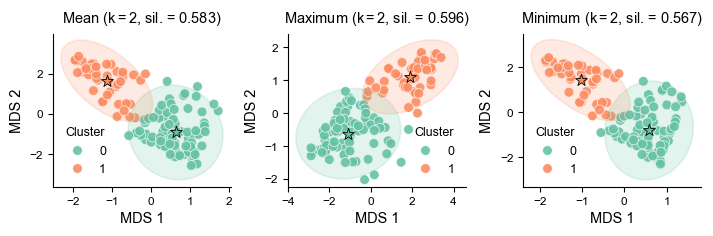

In [52]:
# Figure dimensions
figure_width_cm, figure_height_cm = 18.0, 5.8

# Scatter and ellipses
scatter_size_sym, scatter_alpha_sym = 50, 0.9
ellipse_alpha_sym, ellipse_lw_sym = 0.18, 1.2

# Font sizes
title_fontsize_sym, axis_label_fontsize_sym = 10.5, 10.5
tick_fontsize_sym, legend_fontsize_sym = 8.5, 9.0

previous_autolayout = plt.rcParams["figure.autolayout"]
plt.rcParams["figure.autolayout"] = False

fig, axes = plt.subplots(1, len(sym_modes), figsize=(figure_width_cm / 2.54, figure_height_cm / 2.54), constrained_layout=False)
fig.subplots_adjust(left=0.07, right=0.985, bottom=0.18, top=0.85, wspace=0.32)

for ax, mode in zip(np.atleast_1d(axes), sym_modes):
    ms_df_mode = sym_results[mode]["ms_df"]
    best_mode = sym_results[mode]["best"]

    cluster_levels_mode = sorted(ms_df_mode["OT_cluster_plot"].unique())
    palette_mode = dict(zip(cluster_levels_mode, sns.color_palette("Set2", n_colors=len(cluster_levels_mode))))

    sns.scatterplot(data=ms_df_mode, x="OT_dim1", y="OT_dim2", hue="OT_cluster_plot", hue_order=cluster_levels_mode,
                    palette=palette_mode, edgecolor="white", linewidth=0.6, s=scatter_size_sym,
                    alpha=scatter_alpha_sym, ax=ax)

    for cluster_label in cluster_levels_mode:
        d_mode = ms_df_mode[ms_df_mode["OT_cluster_plot"] == cluster_label]

        if len(d_mode) >= 3:
            add_cov_ellipse(ax, d_mode["OT_dim1"].to_numpy(), d_mode["OT_dim2"].to_numpy(),
                            color=palette_mode[cluster_label], alpha=ellipse_alpha_sym, lw=ellipse_lw_sym)

    ax.set_title(f"{mode_title_map[mode]} ($k={best_mode['k']}$, sil. = {best_mode['silhouette']:.3f})",
                 fontsize=title_fontsize_sym, pad=8)
    ax.set_xlabel("MDS 1", fontsize=axis_label_fontsize_sym)
    ax.set_ylabel("MDS 2", fontsize=axis_label_fontsize_sym)
    ax.tick_params(axis="both", labelsize=tick_fontsize_sym)
    ax.legend(frameon=False, title="Cluster", fontsize=legend_fontsize_sym, title_fontsize=legend_fontsize_sym)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.show()
plt.rcParams["figure.autolayout"] = previous_autolayout

### Interpretation of MDS Dimensions

In [53]:
# HMM metrics
id_col_corrmds, group_col_corrmds, state_col_corrmds = "participant_id", "Group", "State"

df_hmm_corrmds = main["hmm_metrics"].copy()
df_hmm_corrmds[id_col_corrmds] = df_hmm_corrmds[id_col_corrmds].astype(str)

state_values_corrmds = sorted(df_hmm_corrmds[state_col_corrmds].unique(),
                              key=lambda x: int(str(x).replace("State", "")))
state_map_corrmds = {state: f"State {i + 1}" for i, state in enumerate(state_values_corrmds)}
df_hmm_corrmds[state_col_corrmds] = df_hmm_corrmds[state_col_corrmds].replace(state_map_corrmds)

# Reuse the MDS embedding from Fig4
df_mds_corrmds = df_clusters[[id_col_corrmds, "OT_cluster", "OT_dim1", "OT_dim2"]].copy()
df_mds_corrmds[id_col_corrmds] = df_mds_corrmds[id_col_corrmds].astype(str)
df_mds_corrmds = df_mds_corrmds.rename(columns={"OT_dim1": "MDS1", "OT_dim2": "MDS2"})

cluster_name_map_corrmds = {0: "Severe", 1: "Mild"}
cluster_levels_corrmds = ["Severe", "Mild"]
palette_values_corrmds = sns.color_palette("Set2", n_colors=len(cluster_levels_corrmds))
palette_corrmds = dict(zip(cluster_levels_corrmds, palette_values_corrmds))

df_mds_corrmds["ClusterName"] = df_mds_corrmds["OT_cluster"].astype(int).map(cluster_name_map_corrmds)

# Align HMM metrics and MDS coordinates
df_hmm_ms_corrmds = df_hmm_corrmds[df_hmm_corrmds[group_col_corrmds].astype(str).str.upper().eq("MS")].copy()

missing_mds_corrmds = sorted(set(df_hmm_ms_corrmds[id_col_corrmds]) - set(df_mds_corrmds[id_col_corrmds]))
if missing_mds_corrmds:
    raise ValueError(f"Missing MDS coordinates for {len(missing_mds_corrmds)} MS subjects: {missing_mds_corrmds[:10]}")

df_merged_corrmds = df_hmm_ms_corrmds.merge(df_mds_corrmds, on=id_col_corrmds, how="inner", validate="many_to_one")

# Correlation settings
mds_dims_corrmds = ["MDS1", "MDS2"]
states_all_corrmds = list(state_map_corrmds.values())
state_metrics_corrmds = ["FO_soft", "Dwell"]
global_metrics_corrmds = ["SwitchRate"]

corr_cols_corrmds = state_metrics_corrmds + global_metrics_corrmds + mds_dims_corrmds
if df_merged_corrmds[corr_cols_corrmds].isna().any().any():
    raise ValueError("Missing values found in HMM metrics or MDS coordinates used for correlations.")

# Spearman correlations
corr_rows_corrmds = []

for state_corrmds in states_all_corrmds:
    d_state_corrmds = df_merged_corrmds[df_merged_corrmds[state_col_corrmds] == state_corrmds]

    for metric_corrmds in state_metrics_corrmds:
        for mds_var_corrmds in mds_dims_corrmds:
            rho_corrmds, p_corrmds = spearmanr(d_state_corrmds[metric_corrmds], d_state_corrmds[mds_var_corrmds])
            corr_rows_corrmds.append({"State": state_corrmds, "Metric": metric_corrmds, "MDS": mds_var_corrmds,
                                      "rho": float(rho_corrmds), "p": float(p_corrmds), "n": len(d_state_corrmds)})

# Global metric correlations
d_global_corrmds = df_merged_corrmds.drop_duplicates(subset=[id_col_corrmds])

for metric_corrmds in global_metrics_corrmds:
    for mds_var_corrmds in mds_dims_corrmds:
        rho_corrmds, p_corrmds = spearmanr(d_global_corrmds[metric_corrmds], d_global_corrmds[mds_var_corrmds])
        corr_rows_corrmds.append({"State": "Global", "Metric": metric_corrmds, "MDS": mds_var_corrmds,
                                  "rho": float(rho_corrmds), "p": float(p_corrmds), "n": len(d_global_corrmds)})

df_corr_corrmds = pd.DataFrame(corr_rows_corrmds)

# Global FDR correction
reject_corrmds, pvals_fdr_corrmds, _, _ = multipletests(df_corr_corrmds["p"].to_numpy(), method="fdr_bh")
df_corr_corrmds["p_fdr"] = pvals_fdr_corrmds
df_corr_corrmds["significant"] = reject_corrmds

lookup_corrmds = {
    (row.State, row.Metric, row.MDS): (row.rho, row.p_fdr, row.significant, row.n)
    for row in df_corr_corrmds.itertuples(index=False)
}

display(df_corr_corrmds)

,State,Metric,MDS,rho,p,n,p_fdr,significant
0,State 1,FO_soft,MDS1,-0.953427,2.616639e-64,122,1.831647e-63,True
1,State 1,FO_soft,MDS2,0.877497,4.175548e-40,122,1.169154e-39,True
2,State 1,Dwell,MDS1,-0.902493,1.015876e-45,122,3.555567e-45,True
3,State 1,Dwell,MDS2,0.819019,9.878541e-31,122,2.304993e-30,True
4,State 2,FO_soft,MDS1,0.633152,5.076336e-15,122,1.015267e-14,True
5,State 2,FO_soft,MDS2,-0.988322,6.572249e-100,122,9.201149e-99,True
6,State 2,Dwell,MDS1,0.522687,6.592309e-10,122,1.153654e-09,True
7,State 2,Dwell,MDS2,-0.925662,1.745697e-52,122,8.146584e-52,True
8,State 3,FO_soft,MDS1,0.415262,1.973923e-06,122,3.070547e-06,True
9,State 3,FO_soft,MDS2,0.169304,6.228567e-02,122,7.266662e-02,False


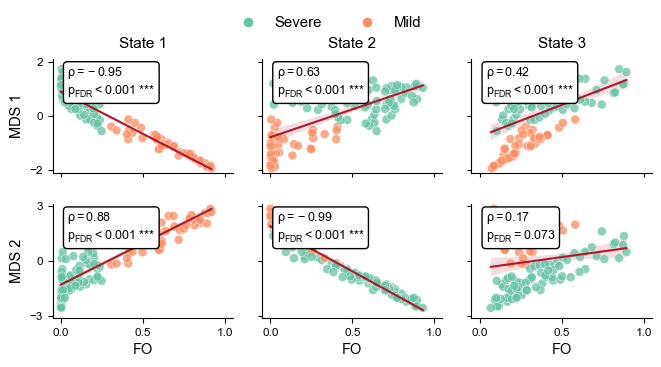

In [54]:
# Plot selection
metric_to_plot_corrmds = "FO_soft"
states_to_plot_corrmds = ["State 1", "State 2", "State 3"]
mds_dims_to_plot_corrmds = ["MDS1", "MDS2"]

mds_label_map_corrmds = {"MDS1": "MDS 1", "MDS2": "MDS 2"}

states_to_plot_corrmds = [state for state in states_to_plot_corrmds
                          if ((df_corr_corrmds["Metric"] == metric_to_plot_corrmds) & (df_corr_corrmds["State"] == state)).any()]
mds_dims_to_plot_corrmds = [mds_var for mds_var in mds_dims_to_plot_corrmds if mds_var in df_corr_corrmds["MDS"].unique()]

if metric_to_plot_corrmds not in df_corr_corrmds["Metric"].unique() or not states_to_plot_corrmds or not mds_dims_to_plot_corrmds:
    raise ValueError("Empty plotting selection: check FO, states and MDS dimensions.")

# Figure dimensions
figure_width_cm_corrmds, figure_height_cm_corrmds = 17.0, 9.0

# Font sizes
title_fontsize_corrmds, axis_label_fontsize_corrmds, tick_fontsize_corrmds = 11.0, 10.5, 8.5
legend_fontsize_corrmds, annotation_fontsize_corrmds = 10.8, 9.0

# Scatter and regression
scatter_size_corrmds, scatter_alpha_corrmds = 42, 0.75
line_color_corrmds = "#b2182b"

nrows_corrmds, ncols_corrmds = len(mds_dims_to_plot_corrmds), len(states_to_plot_corrmds)

previous_autolayout_corrmds = plt.rcParams["figure.autolayout"]
plt.rcParams["figure.autolayout"] = False

# Figure
fig_corrmds = plt.figure(figsize=(figure_width_cm_corrmds / 2.54, figure_height_cm_corrmds / 2.54))
gs_corrmds = gridspec.GridSpec(nrows_corrmds, ncols_corrmds, figure=fig_corrmds, wspace=0.16, hspace=0.28)
fig_corrmds.subplots_adjust(left=0.09, right=0.985, bottom=0.14, top=0.87)

axes_corrmds = np.empty((nrows_corrmds, ncols_corrmds), dtype=object)

# FO-MDS correlations
for r_corrmds, mds_var_corrmds in enumerate(mds_dims_to_plot_corrmds):
    for c_corrmds, state_corrmds in enumerate(states_to_plot_corrmds):
        ax_corrmds = fig_corrmds.add_subplot(gs_corrmds[r_corrmds, c_corrmds])
        axes_corrmds[r_corrmds, c_corrmds] = ax_corrmds

        d_plot_corrmds = df_merged_corrmds.loc[
            df_merged_corrmds[state_col_corrmds] == state_corrmds,
            [metric_to_plot_corrmds, mds_var_corrmds, "ClusterName"]
        ].copy()

        rho_corrmds, p_fdr_corrmds, _, _ = lookup_corrmds[(state_corrmds, metric_to_plot_corrmds, mds_var_corrmds)]

        sns.regplot(data=d_plot_corrmds, x=metric_to_plot_corrmds, y=mds_var_corrmds, scatter=False,
                    line_kws={"color": line_color_corrmds, "linewidth": 1.5}, ax=ax_corrmds)

        sns.scatterplot(data=d_plot_corrmds, x=metric_to_plot_corrmds, y=mds_var_corrmds, hue="ClusterName",
                        hue_order=cluster_levels_corrmds, palette=palette_corrmds, s=scatter_size_corrmds,
                        alpha=scatter_alpha_corrmds, edgecolor="white", linewidth=0.4, legend=False, ax=ax_corrmds)

        ax_corrmds.set_xlim(-0.05, 1.05)
        ax_corrmds.set_xticks([0, 0.5, 1.0])

        if mds_var_corrmds == "MDS1":
            ax_corrmds.set_ylim(-2.1, 2.1)
            ax_corrmds.set_yticks([-2, 0, 2])
        else:
            ax_corrmds.set_ylim(-3.1, 3.1)
            ax_corrmds.set_yticks([-3, 0, 3])

        ax_corrmds.set_title(state_corrmds if r_corrmds == 0 else "", fontsize=title_fontsize_corrmds, pad=8)
        ax_corrmds.set_xlabel("FO" if r_corrmds == nrows_corrmds - 1 else "", fontsize=axis_label_fontsize_corrmds)

        if c_corrmds == 0:
            ax_corrmds.set_ylabel(mds_label_map_corrmds[mds_var_corrmds], fontsize=axis_label_fontsize_corrmds)
        else:
            ax_corrmds.set_ylabel("")
            ax_corrmds.set_yticklabels([])
            ax_corrmds.tick_params(axis="y", length=3)

        if r_corrmds == 0:
            ax_corrmds.set_xticklabels([])
            ax_corrmds.tick_params(axis="x", length=3)

        text_corrmds = rf"$\rho = {rho_corrmds:.2f}$" + "\n" + p_text_fdr(p_fdr_corrmds)
        ax_corrmds.text(0.08, 0.95, text_corrmds, transform=ax_corrmds.transAxes, fontsize=annotation_fontsize_corrmds,
                        ha="left", va="top", bbox=dict(facecolor="white", edgecolor="black", boxstyle="round,pad=0.3"))

        ax_corrmds.tick_params(axis="both", labelsize=tick_fontsize_corrmds)
        ax_corrmds.spines["top"].set_visible(False)
        ax_corrmds.spines["right"].set_visible(False)

# Cluster legend
legend_handles_corrmds = [
    plt.Line2D([0], [0], marker="o", color="white", label=cluster_name,  # type: ignore
               markerfacecolor=palette_corrmds[cluster_name], markeredgecolor="white", markersize=8)
    for cluster_name in cluster_levels_corrmds
]  

fig_corrmds.legend(handles=legend_handles_corrmds, labels=cluster_levels_corrmds, loc="upper center",
                   bbox_to_anchor=(0.5, 1.03), ncol=len(cluster_levels_corrmds), frameon=False,
                   fontsize=legend_fontsize_corrmds)

# Save
tif_path = FIG_DIR / "SI_FigC.tif"
fig_corrmds.savefig(FIG_DIR / "SI_FigC.pdf", dpi=450, bbox_inches="tight")
fig_corrmds.savefig(tif_path, format="tiff", dpi=450, bbox_inches="tight", facecolor="white", transparent=False, pil_kwargs={"compression": "tiff_lzw"})
convert_tiff_to_rgb(tif_path, print_check=False, fig=fig_corrmds)

plt.show()
plt.rcParams["figure.autolayout"] = previous_autolayout_corrmds

### FC-based Clustering

In [55]:
def compute_pac_fccons(C, lower=0.1, upper=0.9):
    '''
    Compute the proportion of ambiguous clustering values in a consensus matrix.
    '''
    C = np.asarray(C, float)
    values = C[np.triu_indices_from(C, k=1)]
    return float(np.mean((values > lower) & (values < upper)))


def rank_biserial(x1, x2):
    '''
    Compute rank-biserial correlation for two independent groups.
    '''
    U, _ = stats.mannwhitneyu(x1, x2, alternative="two-sided")
    return 2 * U / (len(x1) * len(x2)) - 1


def hedges_g(x1, x2):
    '''
    Compute Hedges' g for two independent groups.
    '''
    n1, n2 = len(x1), len(x2)
    if n1 < 2 or n2 < 2:
        return np.nan

    v1, v2 = np.var(x1, ddof=1), np.var(x2, ddof=1)
    dof = n1 + n2 - 2
    if dof <= 0:
        return np.nan

    sp2 = ((n1 - 1) * v1 + (n2 - 1) * v2) / dof
    if sp2 <= 0:
        return np.nan

    d = (np.mean(x1) - np.mean(x2)) / np.sqrt(sp2)
    J = 1 - 3 / (4 * dof - 1)
    return d * J


def compare_ot_cluster_clinical(ms_df, cluster_col="OT_cluster", test_mode="ttest"):
    '''
    Compare clinical outcomes between the two OT-derived MS clusters (no covariate adjustment).
    '''
    # ttest (primary): Welch for continuous outcomes, Mann-Whitney sensitivity.
    # Mannwhitney: Mann-whitney on all outcomes for sensitivity (almost same results)
    if test_mode not in {"ttest", "mannwhitney"}:
        raise ValueError("test_mode must be 'ttest' or 'mannwhitney'")

    df = ms_df.copy()

    for col in ["EDSS", "SDMT", "BPF", "lesion_load"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    if (df["lesion_load"].dropna() < 0).any():
        raise ValueError("lesion_load contains negative values")

    df["lesion_load_log1p"] = np.log1p(df["lesion_load"])

    specs = [
        ("EDSS", "EDSS", "ordinal/raw"),
        ("SDMT", "SDMT", "raw"),
        ("BPF", "BPF", "raw"),
        ("lesion_load", "lesion_load_log1p", "log1p(lesion_load)")
    ]

    rows = []

    for variable, column, scale in specs:
        use_welch = test_mode == "ttest" and variable != "EDSS"

        if use_welch:
            x0 = df.loc[df[cluster_col] == 0, column].dropna().to_numpy(float)
            x1 = df.loc[df[cluster_col] == 1, column].dropna().to_numpy(float)
            res = stats.ttest_ind(x0, x1, equal_var=False, alternative="two-sided")
            test, stat_name = "Welch t-test", "t"
            effect, effect_name = hedges_g(x0, x1), "Hedges' g"

        else:
            x0 = df.loc[df[cluster_col] == 0, variable].dropna().to_numpy(float)
            x1 = df.loc[df[cluster_col] == 1, variable].dropna().to_numpy(float)
            res = stats.mannwhitneyu(x0, x1, alternative="two-sided")
            test, stat_name = "Mann-Whitney U", "U"
            effect, effect_name = rank_biserial(x0, x1), "Rank-biserial r"
            scale = "ordinal/raw" if variable == "EDSS" else "raw"

        rows.append({"variable": variable, "analysis_scale": scale, "test": test, "contrast": "0 vs 1",
                     "stat_name": stat_name, "stat": float(res.statistic), "effect": float(effect),  # type:ignore
                     "effect_size": effect_name, "p_raw": float(res.pvalue)})  # type:ignore

    results = pd.DataFrame(rows)
    results["p_fdr_bh"] = multipletests(results["p_raw"], method="fdr_bh")[1]

    return results

In [56]:
# Data
id_col_fccons, group_col_fccons = "participant_id", "group"
clinical_features_fccons = ["EDSS", "BPF", "SDMT", "lesion_load"]
clinical_label_map_fccons = {"EDSS": "EDSS", "BPF": "BPF", "SDMT": "SDMT", "lesion_load": "Lesion Load"}
clinical_levels_fccons = [clinical_label_map_fccons[feature] for feature in clinical_features_fccons]

fcs_all_fccons = np.asarray(fcs_all, float)
df_meta_fccons = df_sel.copy()
df_meta_fccons.index = df_meta_fccons.index.astype(str)

if fcs_all_fccons.ndim != 3 or fcs_all_fccons.shape[1] != fcs_all_fccons.shape[2]:
    raise ValueError(f"fcs_all must have shape subjects x parcels x parcels, found {fcs_all_fccons.shape}.")
if len(fcs_all_fccons) != len(df_meta_fccons):
    raise ValueError("fcs_all and df_sel have incompatible subject dimensions.")

missing_features_fccons = [feature for feature in clinical_features_fccons if feature not in df_meta_fccons.columns]
if missing_features_fccons:
    raise KeyError(f"Missing clinical columns: {missing_features_fccons}")

groups_fccons = df_meta_fccons[group_col_fccons].astype(str).str.strip().str.upper().to_numpy()
ms_mask_fccons = groups_fccons == "MS"
ms_idx_fccons = np.where(ms_mask_fccons)[0]

fcs_ms_fccons = fcs_all_fccons[ms_idx_fccons]
df_ms_fccons = df_meta_fccons.iloc[ms_idx_fccons].copy().reset_index()

print(f"MS FC matrices: {fcs_ms_fccons.shape}")

# Vectorize and standardize FC edges
n_parcels_fccons = fcs_ms_fccons.shape[1]
upper_idx_fccons = np.triu_indices(n_parcels_fccons, k=1)
fcs_ms_vectorized_fccons = fcs_ms_fccons[:, upper_idx_fccons[0], upper_idx_fccons[1]]

fc_scaler_fccons = StandardScaler()
fcs_ms_scaled_fccons = fc_scaler_fccons.fit_transform(fcs_ms_vectorized_fccons)

# PCA decomposition
pca_fccons = PCA(svd_solver="full")
fcs_ms_pca_fccons = pca_fccons.fit_transform(fcs_ms_scaled_fccons)
pca_explained_ratio_fccons = pca_fccons.explained_variance_ratio_
pca_cumulative_ratio_fccons = np.cumsum(pca_explained_ratio_fccons)

# PCA silhouette analysis
pca_k_range_fccons = range(2, 6)
pca_silhouette_rows_fccons = []

for n_components_fccons in range(1, pca_fccons.n_components_ + 1):
    X_pca_scan_fccons = fcs_ms_pca_fccons[:, :n_components_fccons]

    for n_clusters_fccons in pca_k_range_fccons:
        labels_scan_fccons = AgglomerativeClustering(n_clusters=n_clusters_fccons, metric="euclidean",
                                                     linkage="ward").fit_predict(X_pca_scan_fccons)
        pca_silhouette_rows_fccons.append({
            "n_components": n_components_fccons,
            "n_clusters": n_clusters_fccons,
            "silhouette": float(silhouette_score(X_pca_scan_fccons, labels_scan_fccons))
        })

df_pca_silhouette_fccons = pd.DataFrame(pca_silhouette_rows_fccons)
best_pca_silhouette_fccons = df_pca_silhouette_fccons.loc[df_pca_silhouette_fccons["silhouette"].idxmax()]  # type: ignore

# Final PCA clustering
pca_cluster_components_fccons, pca_cluster_k_fccons = 5, 2

pca_labels_fccons = AgglomerativeClustering(n_clusters=pca_cluster_k_fccons, metric="euclidean",
                                            linkage="ward").fit_predict(
    fcs_ms_pca_fccons[:, :pca_cluster_components_fccons]
).astype(int)

pca_silhouette_fccons = silhouette_score(
    fcs_ms_pca_fccons[:, :pca_cluster_components_fccons], pca_labels_fccons
)

print("\nPCA clustering")
print(f"Components = {pca_cluster_components_fccons}")
print(f"Cumulative explained variance = {pca_cumulative_ratio_fccons[pca_cluster_components_fccons - 1]:.4f}")
print(f"Silhouette = {pca_silhouette_fccons:.4f}")
print("Cluster sizes:", dict(zip(*np.unique(pca_labels_fccons, return_counts=True))))

# UMAP consensus settings
umap_consensus_k_fccons, umap_consensus_components_fccons = 2, 5
umap_consensus_metric_fccons, umap_consensus_runs_fccons = "correlation", 500  # tried also with metric euclidean and cosine
pac_lower_fccons, pac_upper_fccons = 0.1, 0.9

# UMAP consensus clustering
n_subjects_fccons = len(fcs_ms_scaled_fccons)
coassociation_fccons = np.zeros((n_subjects_fccons, n_subjects_fccons), dtype=float)
pac_history_fccons = []

for seed_fccons in range(umap_consensus_runs_fccons):
    embedding_run_fccons = np.asarray(
        umap.UMAP(n_components=umap_consensus_components_fccons, metric=umap_consensus_metric_fccons,
                  random_state=seed_fccons, n_jobs=1).fit_transform(fcs_ms_scaled_fccons)
    )

    labels_run_fccons = AgglomerativeClustering(n_clusters=umap_consensus_k_fccons, metric="euclidean",
                                                linkage="ward").fit_predict(embedding_run_fccons)

    for cluster_fccons in range(umap_consensus_k_fccons):
        idx_cluster_fccons = np.where(labels_run_fccons == cluster_fccons)[0]
        coassociation_fccons[np.ix_(idx_cluster_fccons, idx_cluster_fccons)] += 1.0

    consensus_current_fccons = coassociation_fccons / (seed_fccons + 1)
    np.fill_diagonal(consensus_current_fccons, 1.0)
    pac_history_fccons.append(compute_pac_fccons(consensus_current_fccons, lower=pac_lower_fccons, upper=pac_upper_fccons))

# Final UMAP consensus clustering
C_consensus_fccons = coassociation_fccons / umap_consensus_runs_fccons
np.fill_diagonal(C_consensus_fccons, 1.0)

D_consensus_fccons = 1.0 - C_consensus_fccons
np.fill_diagonal(D_consensus_fccons, 0.0)

umap_consensus_labels_raw_fccons = AgglomerativeClustering(
    n_clusters=umap_consensus_k_fccons, metric="precomputed", linkage="average"
).fit_predict(D_consensus_fccons).astype(int)

final_pac_fccons = float(pac_history_fccons[-1])
umap_consensus_silhouette_fccons = silhouette_score(
    D_consensus_fccons, umap_consensus_labels_raw_fccons, metric="precomputed"
)

print("\nUMAP consensus clustering")
print(f"Runs completed = {umap_consensus_runs_fccons}")
print(f"Final PAC = {final_pac_fccons:.4f}")
print(f"Consensus-distance silhouette = {umap_consensus_silhouette_fccons:.4f}")
print("Raw cluster sizes:", dict(zip(*np.unique(umap_consensus_labels_raw_fccons, return_counts=True))))

# Align UMAP labels with PCA labels
contingency_fccons = pd.crosstab(pd.Series(umap_consensus_labels_raw_fccons, name="UMAP consensus"),
                                 pd.Series(pca_labels_fccons, name="PCA"))
row_idx_fccons, col_idx_fccons = linear_sum_assignment(-contingency_fccons.to_numpy())
label_alignment_fccons = {contingency_fccons.index[i]: contingency_fccons.columns[j]
                          for i, j in zip(row_idx_fccons, col_idx_fccons)}

umap_consensus_labels_fccons = np.asarray(
    [label_alignment_fccons[label] for label in umap_consensus_labels_raw_fccons], dtype=int
)

ari_pca_umap_fccons = adjusted_rand_score(pca_labels_fccons, umap_consensus_labels_fccons)
nmi_pca_umap_fccons = normalized_mutual_info_score(pca_labels_fccons, umap_consensus_labels_fccons)

print(f"ARI between PCA and UMAP consensus = {ari_pca_umap_fccons:.3f}")
print(f"NMI between PCA and UMAP consensus = {nmi_pca_umap_fccons:.3f}")
print("Aligned cluster sizes:", dict(zip(*np.unique(umap_consensus_labels_fccons, return_counts=True))))

# Store cluster assignments
df_analysis_fccons = df_ms_fccons.copy()
df_analysis_fccons["PCA_Cluster"] = pca_labels_fccons
df_analysis_fccons["UMAP_Consensus"] = umap_consensus_labels_fccons

# Clinical comparisons using the main-analysis function
method_cluster_cols_fccons = {"PCA": "PCA_Cluster", "UMAP consensus": "UMAP_Consensus"}
clinical_results_fccons = []

for method_fccons, cluster_col_fccons in method_cluster_cols_fccons.items():
    d_stats_fccons = compare_ot_cluster_clinical(df_analysis_fccons, cluster_col=cluster_col_fccons, test_mode="ttest")
    d_stats_fccons.insert(0, "Method", method_fccons)
    clinical_results_fccons.append(d_stats_fccons)

df_clinical_fccons = pd.concat(clinical_results_fccons, ignore_index=True)

display(df_clinical_fccons)

# Normalize clinical variables for plotting only
df_scores_fccons = df_analysis_fccons[[id_col_fccons, "PCA_Cluster", "UMAP_Consensus"] + clinical_features_fccons].copy()

for feature_fccons in clinical_features_fccons:
    values_fccons = pd.to_numeric(df_scores_fccons[feature_fccons], errors="coerce")
    feature_min_fccons, feature_max_fccons = values_fccons.min(), values_fccons.max()

    if pd.isna(feature_min_fccons) or pd.isna(feature_max_fccons):
        df_scores_fccons[f"{feature_fccons}_normalized"] = np.nan
    elif feature_max_fccons == feature_min_fccons:
        df_scores_fccons[f"{feature_fccons}_normalized"] = 0.0
    else:
        df_scores_fccons[f"{feature_fccons}_normalized"] = (
            values_fccons - feature_min_fccons
        ) / (feature_max_fccons - feature_min_fccons)

MS FC matrices: (122, 100, 100)

PCA clustering
Components = 5
Cumulative explained variance = 0.3420
Silhouette = 0.4265
Cluster sizes: {0: 104, 1: 18}

UMAP consensus clustering
Runs completed = 500
Final PAC = 0.1932
Consensus-distance silhouette = 0.9080
Raw cluster sizes: {0: 84, 1: 38}
ARI between PCA and UMAP consensus = -0.045
NMI between PCA and UMAP consensus = 0.018
Aligned cluster sizes: {0: 84, 1: 38}


,Method,variable,analysis_scale,test,contrast,stat_name,stat,effect,effect_size,p_raw,p_fdr_bh
0,PCA,EDSS,ordinal/raw,Mann-Whitney U,0 vs 1,U,861.500000,-0.079594,Rank-biserial r,0.586978,0.882277
1,PCA,SDMT,raw,Welch t-test,0 vs 1,t,-0.165726,-0.038058,Hedges' g,0.869681,0.882277
2,PCA,BPF,raw,Welch t-test,0 vs 1,t,0.149851,0.042431,Hedges' g,0.882277,0.882277
3,PCA,lesion_load,log1p(lesion_load),Welch t-test,0 vs 1,t,-2.548504,-0.416207,Hedges' g,0.014410,0.057640
4,UMAP consensus,EDSS,ordinal/raw,Mann-Whitney U,0 vs 1,U,1751.500000,0.097431,Rank-biserial r,0.383558,0.401106
5,UMAP consensus,SDMT,raw,Welch t-test,0 vs 1,t,-0.844597,-0.162952,Hedges' g,0.401106,0.401106
6,UMAP consensus,BPF,raw,Welch t-test,0 vs 1,t,-2.053507,-0.367088,Hedges' g,0.042989,0.171957
7,UMAP consensus,lesion_load,log1p(lesion_load),Welch t-test,0 vs 1,t,1.390712,0.252305,Hedges' g,0.167951,0.335902


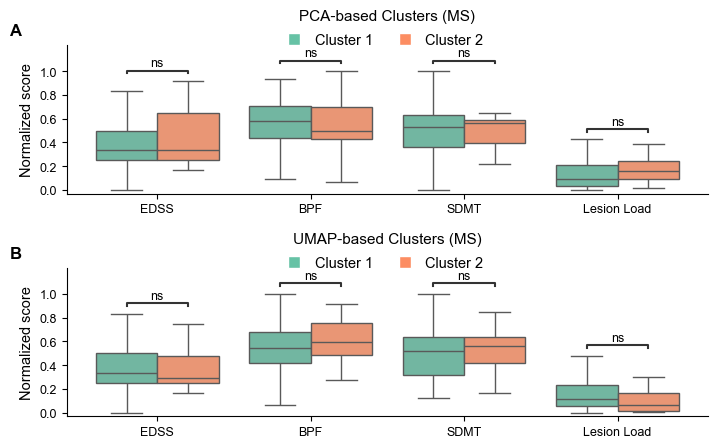

In [57]:
# Plot dataframe
cluster_name_map_fccons = {0: "Cluster 1", 1: "Cluster 2"}
plot_rows_fccons = []

for method_fccons, cluster_col_fccons in method_cluster_cols_fccons.items():
    for feature_fccons in clinical_features_fccons:
        d_plot_fccons = df_scores_fccons[
            [id_col_fccons, cluster_col_fccons, f"{feature_fccons}_normalized"]
        ].copy()

        d_plot_fccons = d_plot_fccons.rename(
            columns={cluster_col_fccons: "Cluster", f"{feature_fccons}_normalized": "Score"}
        )
        d_plot_fccons["Method"] = method_fccons
        d_plot_fccons["Feature"] = clinical_label_map_fccons[feature_fccons]
        d_plot_fccons["ClusterName"] = d_plot_fccons["Cluster"].map(cluster_name_map_fccons)

        plot_rows_fccons.append(
            d_plot_fccons[[id_col_fccons, "Method", "Feature", "Cluster", "ClusterName", "Score"]]
        )

df_plot_fccons = pd.concat(plot_rows_fccons, ignore_index=True).dropna(subset=["Score"])

clinical_p_lookup_fccons = {
    (row.Method, clinical_label_map_fccons[row.variable]): row.p_fdr_bh
    for row in df_clinical_fccons.itertuples(index=False)
}

# Figure dimensions
figure_width_cm_fccons, figure_height_cm_fccons = 18.0, 11.5

# Font sizes
title_fontsize_fccons, axis_label_fontsize_fccons, tick_fontsize_fccons = 11, 10.5, 9.0
legend_fontsize_fccons, annotation_fontsize_fccons, panel_label_fontsize_fccons = 10.5, 9.0, 12

# Clusters and methods
cluster_levels_fccons = ["Cluster 1", "Cluster 2"]
palette_values_fccons = sns.color_palette("Set2", n_colors=len(cluster_levels_fccons))
palette_fccons = dict(zip(cluster_levels_fccons, palette_values_fccons))
method_order_fccons = ["PCA", "UMAP consensus"]
method_title_map_fccons = {"PCA": "PCA-based Clusters (MS)", "UMAP consensus": "UMAP-based Clusters (MS)"}

previous_autolayout_fccons = plt.rcParams["figure.autolayout"]
plt.rcParams["figure.autolayout"] = False

# Legend handles
legend_handles_fccons = [
    plt.Line2D([0], [0], marker="s", color="white", label=cluster_name_fccons,  # type:ignore
               markerfacecolor=palette_fccons[cluster_name_fccons], markeredgecolor="white", markersize=8)
    for cluster_name_fccons in cluster_levels_fccons
]

# Figure
fig_fccons = plt.figure(figsize=(figure_width_cm_fccons / 2.54, figure_height_cm_fccons / 2.54), constrained_layout=False)
gs_fccons = gridspec.GridSpec(2, 1, figure=fig_fccons, hspace=0.5)
axes_fccons = [fig_fccons.add_subplot(gs_fccons[row_fccons, 0]) for row_fccons in range(2)]
fig_fccons.subplots_adjust(left=0.08, right=0.985, bottom=0.09, top=0.91)

for ax_fccons, method_fccons in zip(axes_fccons, method_order_fccons):
    d_method_fccons = df_plot_fccons[df_plot_fccons["Method"] == method_fccons].copy()

    sns.boxplot(data=d_method_fccons, x="Feature", y="Score", hue="ClusterName",
                order=clinical_levels_fccons, hue_order=cluster_levels_fccons,
                palette=palette_fccons, showfliers=False, ax=ax_fccons)

    if ax_fccons.get_legend() is not None:
        ax_fccons.get_legend().remove()

    pvals_fccons = [clinical_p_lookup_fccons[(method_fccons, feature_fccons)]
                    for feature_fccons in clinical_levels_fccons]
    pairs_fccons = [((feature_fccons, cluster_levels_fccons[0]), (feature_fccons, cluster_levels_fccons[1]))
                    for feature_fccons in clinical_levels_fccons]

    annot_fccons = Annotator(ax_fccons, pairs=pairs_fccons, data=d_method_fccons, x="Feature", y="Score",
                             hue="ClusterName", order=clinical_levels_fccons, hue_order=cluster_levels_fccons)
    annot_fccons.configure(test=None, text_format="star", loc="inside", verbose=False, hide_non_significant=False,
                           fontsize=annotation_fontsize_fccons,
                           pvalue_thresholds=[(0.001, "***"), (0.01, "**"), (0.05, "*"), (1.00, "ns")])
    annot_fccons.set_pvalues(pvals_fccons)
    annot_fccons.annotate()

    ax_fccons.set_title(method_title_map_fccons[method_fccons], fontsize=title_fontsize_fccons, pad=18)
    ax_fccons.legend(handles=legend_handles_fccons, labels=cluster_levels_fccons, loc="upper right",
                     bbox_to_anchor=(0.67, 1.17), ncol=len(cluster_levels_fccons), frameon=False,
                     fontsize=legend_fontsize_fccons, handletextpad=0.4, columnspacing=1.2)

    ax_fccons.set_xlabel("")
    ax_fccons.set_ylabel("Normalized score", fontsize=axis_label_fontsize_fccons)
    ax_fccons.set_ylim(-0.03, 1.22)
    ax_fccons.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
    ax_fccons.set_xticks(np.arange(len(clinical_levels_fccons)))
    ax_fccons.set_xticklabels(clinical_levels_fccons, fontsize=tick_fontsize_fccons)
    ax_fccons.tick_params(axis="y", labelsize=tick_fontsize_fccons)
    ax_fccons.spines["top"].set_visible(False)
    ax_fccons.spines["right"].set_visible(False)

# Panel labels
fig_fccons.canvas.draw()
pos_a_fccons, pos_b_fccons = axes_fccons[0].get_position(), axes_fccons[1].get_position()

fig_fccons.text(pos_a_fccons.x0 - 0.08, pos_a_fccons.y1 + 0.015, "A", fontsize=panel_label_fontsize_fccons,
                fontweight="bold", ha="left", va="bottom")
fig_fccons.text(pos_b_fccons.x0 - 0.08, pos_b_fccons.y1 + 0.015, "B", fontsize=panel_label_fontsize_fccons,
                fontweight="bold", ha="left", va="bottom")

# Save
tif_path = FIG_DIR / "SI_FigD.tif"
fig_fccons.savefig(FIG_DIR / "SI_FigD.pdf", dpi=450, bbox_inches="tight")
fig_fccons.savefig(tif_path, format="tiff", dpi=450, bbox_inches="tight", facecolor="white", transparent=False, pil_kwargs={"compression": "tiff_lzw"})
convert_tiff_to_rgb(tif_path, print_check=False, fig=fig_fccons)

plt.show()
plt.rcParams["figure.autolayout"] = previous_autolayout_fccons

In [26]:
# PCA dimensionality robustness
max_pcs_fccons = min(fcs_ms_scaled_fccons.shape[0] - 1, fcs_ms_scaled_fccons.shape[1])
pca_components_test_fccons = [2, 5, 10, 25, 60, max_pcs_fccons]
pca_robustness_rows_fccons = []

for n_components_fccons in pca_components_test_fccons:
    X_pca_fccons = fcs_ms_pca_fccons[:, :n_components_fccons]

    labels_fccons = AgglomerativeClustering(
        n_clusters=2, metric="euclidean", linkage="ward"
    ).fit_predict(X_pca_fccons).astype(int)

    silhouette_fccons = silhouette_score(X_pca_fccons, labels_fccons)

    df_pca_test_fccons = df_ms_fccons.copy()
    df_pca_test_fccons["PCA_Cluster"] = labels_fccons

    df_stats_fccons = compare_ot_cluster_clinical(
        df_pca_test_fccons, cluster_col="PCA_Cluster", test_mode="ttest"
    )

    n0_fccons, n1_fccons = np.bincount(labels_fccons, minlength=2)

    for row_fccons in df_stats_fccons.itertuples(index=False):
        pca_robustness_rows_fccons.append({
            "n_components": n_components_fccons,
            "silhouette": silhouette_fccons,
            "n_cluster_0": int(n0_fccons),
            "n_cluster_1": int(n1_fccons),
            "variable": row_fccons.variable,
            "test": row_fccons.test,
            "effect": row_fccons.effect,
            "p_raw": row_fccons.p_raw,
            "p_fdr_bh": row_fccons.p_fdr_bh
        })

df_pca_robustness_fccons = pd.DataFrame(pca_robustness_rows_fccons)
df_pca_robustness_fccons["significant"] = df_pca_robustness_fccons["p_fdr_bh"] < 0.05

# Compact summary
df_pca_pvalues_fccons = (
    df_pca_robustness_fccons
    .pivot(index="n_components", columns="variable", values="p_fdr_bh")
    .reset_index()
)

df_pca_summary_fccons = (
    df_pca_robustness_fccons
    .groupby("n_components", as_index=False)
    .agg(
        silhouette=("silhouette", "first"),
        n_cluster_0=("n_cluster_0", "first"),
        n_cluster_1=("n_cluster_1", "first"),
        n_significant=("significant", "sum")
    )
)

df_pca_summary_fccons = df_pca_summary_fccons.merge(df_pca_pvalues_fccons, on="n_components")

display(df_pca_summary_fccons)

# Any FDR-significant clinical differences?
df_pca_significant_fccons = df_pca_robustness_fccons[df_pca_robustness_fccons["significant"]].copy()

if df_pca_significant_fccons.empty:
    print("No clinical or structural comparison is significant after FDR correction across the tested PCA dimensionalities.")
else:
    print("FDR-significant comparisons found for some PCA dimensionalities:")
    display(
        df_pca_significant_fccons[
            ["n_components", "silhouette", "variable", "test", "effect", "p_raw", "p_fdr_bh"]
        ].reset_index(drop=True)
    )

# UMAP dimensionality robustness
umap_components_test_fccons = [2, 5, 10]
umap_robustness_rows_fccons = []

for n_components_fccons in umap_components_test_fccons:
    if n_components_fccons == umap_consensus_components_fccons:
        labels_fccons = umap_consensus_labels_raw_fccons.copy()
        pac_fccons = final_pac_fccons
        silhouette_fccons = umap_consensus_silhouette_fccons

    else:
        coassociation_test_fccons = np.zeros((n_subjects_fccons, n_subjects_fccons), dtype=float)

        for seed_fccons in range(umap_consensus_runs_fccons):
            embedding_fccons = np.asarray(
                umap.UMAP(n_components=n_components_fccons, metric=umap_consensus_metric_fccons,
                          random_state=seed_fccons, n_jobs=1).fit_transform(fcs_ms_scaled_fccons)
            )

            labels_run_fccons = AgglomerativeClustering(
                n_clusters=umap_consensus_k_fccons, metric="euclidean", linkage="ward"
            ).fit_predict(embedding_fccons)

            for cluster_fccons in range(umap_consensus_k_fccons):
                idx_cluster_fccons = np.where(labels_run_fccons == cluster_fccons)[0]
                coassociation_test_fccons[np.ix_(idx_cluster_fccons, idx_cluster_fccons)] += 1.0

        C_consensus_test_fccons = coassociation_test_fccons / umap_consensus_runs_fccons
        np.fill_diagonal(C_consensus_test_fccons, 1.0)

        D_consensus_test_fccons = 1.0 - C_consensus_test_fccons
        np.fill_diagonal(D_consensus_test_fccons, 0.0)

        labels_fccons = AgglomerativeClustering(
            n_clusters=umap_consensus_k_fccons, metric="precomputed", linkage="average"
        ).fit_predict(D_consensus_test_fccons).astype(int)

        pac_fccons = compute_pac_fccons(C_consensus_test_fccons, lower=pac_lower_fccons, upper=pac_upper_fccons)
        silhouette_fccons = silhouette_score(D_consensus_test_fccons, labels_fccons, metric="precomputed")

    df_umap_test_fccons = df_ms_fccons.copy()
    df_umap_test_fccons["UMAP_Consensus"] = labels_fccons

    df_stats_fccons = compare_ot_cluster_clinical(
        df_umap_test_fccons, cluster_col="UMAP_Consensus", test_mode="ttest"
    )

    n0_fccons, n1_fccons = np.bincount(labels_fccons, minlength=2)

    for row_fccons in df_stats_fccons.itertuples(index=False):
        umap_robustness_rows_fccons.append({
            "n_components": n_components_fccons,
            "PAC": pac_fccons,
            "silhouette": silhouette_fccons,
            "n_cluster_0": int(n0_fccons),
            "n_cluster_1": int(n1_fccons),
            "variable": row_fccons.variable,
            "test": row_fccons.test,
            "effect": row_fccons.effect,
            "p_raw": row_fccons.p_raw,
            "p_fdr_bh": row_fccons.p_fdr_bh
        })

df_umap_robustness_fccons = pd.DataFrame(umap_robustness_rows_fccons)
df_umap_robustness_fccons["significant"] = df_umap_robustness_fccons["p_fdr_bh"] < 0.05

# Compact summary
df_umap_pvalues_fccons = (
    df_umap_robustness_fccons
    .pivot(index="n_components", columns="variable", values="p_fdr_bh")
    .reset_index()
)

df_umap_summary_fccons = (
    df_umap_robustness_fccons
    .groupby("n_components", as_index=False)
    .agg(
        PAC=("PAC", "first"),
        silhouette=("silhouette", "first"),
        n_cluster_0=("n_cluster_0", "first"),
        n_cluster_1=("n_cluster_1", "first"),
        n_significant=("significant", "sum")
    )
)

df_umap_summary_fccons = df_umap_summary_fccons.merge(
    df_umap_pvalues_fccons, on="n_components"
)

display(df_umap_summary_fccons)

# Any FDR-significant clinical differences?
df_umap_significant_fccons = (
    df_umap_robustness_fccons[df_umap_robustness_fccons["significant"]].copy()
)

if df_umap_significant_fccons.empty:
    print("No clinical or structural comparison is significant after FDR correction across the tested UMAP dimensionalities.")
else:
    print("FDR-significant comparisons found for some UMAP dimensionalities:")
    display(
        df_umap_significant_fccons[
            ["n_components", "PAC", "silhouette", "variable",
             "test", "effect", "p_raw", "p_fdr_bh"]
        ].reset_index(drop=True)
    )

,n_components,silhouette,n_cluster_0,n_cluster_1,n_significant,BPF,EDSS,SDMT,lesion_load
0,2,0.557269,102,20,0,0.885416,0.793587,0.885416,0.050966
1,5,0.426478,104,18,0,0.882277,0.882277,0.882277,0.057640
2,10,0.351969,104,18,0,0.882277,0.882277,0.882277,0.057640
3,25,0.253514,104,18,0,0.927747,0.927747,0.927747,0.078156
4,60,0.188252,104,18,0,0.882277,0.882277,0.882277,0.057640
5,121,0.157387,103,19,0,0.896763,0.896763,0.896763,0.057327


No clinical or structural comparison is significant after FDR correction across the tested PCA dimensionalities.


,n_components,PAC,silhouette,n_cluster_0,n_cluster_1,n_significant,BPF,EDSS,SDMT,lesion_load
0,2,0.373933,0.855692,37,85,0,0.152120,0.350295,0.350295,0.350295
1,5,0.193199,0.908014,84,38,0,0.171957,0.401106,0.401106,0.335902
2,10,0.206070,0.897560,84,38,0,0.171957,0.401106,0.401106,0.335902


No clinical or structural comparison is significant after FDR correction across the tested UMAP dimensionalities.


### FCs States

In [72]:
# Panel Data
fc_states = np.asarray(main["fcs_orig"], float)
n_states = fc_states.shape[0]

if fc_states.ndim != 3 or fc_states.shape[1] != fc_states.shape[2]:
    raise ValueError(f"fcs_orig must have shape states x parcels x parcels, found {fc_states.shape}.")
if len(network_labels) != fc_states.shape[1]:
    raise ValueError("network_labels and fcs_orig have incompatible parcel dimensions.")

pair_indices = [(i, j) for i in range(n_states) for j in range(i + 1, n_states)]
pairwise_fc_diff = [fc_states[j] - fc_states[i] for i, j in pair_indices]

fc_titles = [f"FC - State {k + 1}" for k in range(n_states)]
diff_titles = [rf"$\Delta$FC (State {j + 1} - State {i + 1})" for i, j in pair_indices]

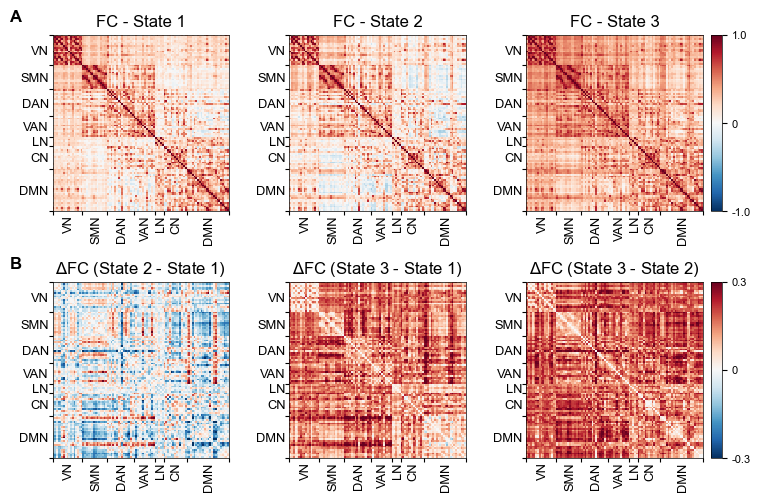

In [73]:
# Plot settings
figure_width_cm, figure_height_cm = 18.0, 12.5
fc_cmap, diff_cmap = "RdBu_r", "RdBu_r"
fc_vmax = np.percentile(np.abs(fc_states), 99)  
diff_vmax = np.percentile(np.abs(np.stack(pairwise_fc_diff, axis=0)), 99)  

fc_vminvmax = [[-fc_vmax, fc_vmax] for _ in range(n_states)]
diff_vminvmax = [[-diff_vmax, diff_vmax] for _ in range(len(pairwise_fc_diff))]

label_pad_x, label_pad_y = 2.2, 2.2
x_label_shift, y_label_shift = 0.82, 0.82
cbar_width, cbar_pad = 0.015, 0.012

previous_autolayout = plt.rcParams["figure.autolayout"]
plt.rcParams["figure.autolayout"] = False

# Figure layout
fig = plt.figure(figsize=(figure_width_cm / 2.54, figure_height_cm / 2.54))
outer_gs = gridspec.GridSpec(2, 1, figure=fig, height_ratios=[1, 1], hspace=0.4)

fc_gs = gridspec.GridSpecFromSubplotSpec(1, n_states, subplot_spec=outer_gs[0], wspace=0.28)
diff_gs = gridspec.GridSpecFromSubplotSpec(1, len(pairwise_fc_diff), subplot_spec=outer_gs[1], wspace=0.28)

axes_fc = [fig.add_subplot(fc_gs[0, i]) for i in range(n_states)]
axes_diff = [fig.add_subplot(diff_gs[0, i]) for i in range(len(pairwise_fc_diff))]

fig.subplots_adjust(left=0.00, right=0.93, bottom=0.08, top=0.94)

# State FC matrices
plot_matrices(list(fc_states), network_labels=network_labels, network_names=network_names,
              titles=fc_titles, vminvmax=fc_vminvmax, center=0, cmap=fc_cmap,
              figsize_per_matrix=(2.9, 2.8), sort=True, labels_for=list(range(n_states)),
              label_pad_x=label_pad_x, label_pad_y=label_pad_y, label_size=3.2,
              x_label_shift=x_label_shift, y_label_shift=y_label_shift,
              axes=axes_fc, cbar=False)

for ax, title in zip(axes_fc, fc_titles):
    ax.set_title(title, fontsize=12, pad=6)

# Pairwise FC differences
plot_matrices(pairwise_fc_diff, network_labels=network_labels, network_names=network_names,
              titles=diff_titles, vminvmax=diff_vminvmax, center=0, cmap=diff_cmap,
              figsize_per_matrix=(2.9, 2.8), sort=True, labels_for=list(range(len(pairwise_fc_diff))),
              label_pad_x=label_pad_x, label_pad_y=label_pad_y, label_size=3.2,
              x_label_shift=x_label_shift, y_label_shift=y_label_shift,
              axes=axes_diff, cbar=False)

for ax, title in zip(axes_diff, diff_titles):
    ax.set_title(title, fontsize=12, pad=6)

# Manual colorbars
fig.canvas.draw()

pos_fc = axes_fc[-1].get_position()
cax_fc = fig.add_axes([pos_fc.x1 + cbar_pad, pos_fc.y0, cbar_width, pos_fc.height])  # type: ignore
cbar_fc = fig.colorbar(axes_fc[0].collections[0], cax=cax_fc)
cbar_fc.set_ticks([-fc_vmax, 0, fc_vmax])  # type: ignore
cbar_fc.set_ticklabels([f"{-fc_vmax:.1f}", "0", f"{fc_vmax:.1f}"])
cbar_fc.outline.set_edgecolor("black")  # type: ignore
cbar_fc.outline.set_linewidth(0.5)  # type: ignore
cbar_fc.ax.tick_params(labelsize=8)

pos_diff = axes_diff[-1].get_position()
cax_diff = fig.add_axes([pos_diff.x1 + cbar_pad, pos_diff.y0, cbar_width, pos_diff.height])  # type: ignore
cbar_diff = fig.colorbar(axes_diff[0].collections[0], cax=cax_diff)
cbar_diff.set_ticks([-diff_vmax, 0, diff_vmax])  # type: ignore
cbar_diff.set_ticklabels([f"{-diff_vmax:.1f}", "0", f"{diff_vmax:.1f}"])
cbar_diff.outline.set_edgecolor("black")  # type: ignore
cbar_diff.outline.set_linewidth(0.5)  # type: ignore
cbar_diff.ax.tick_params(labelsize=8)

# Panel labels
fig.canvas.draw()

pos_a, pos_b = axes_fc[0].get_position(), axes_diff[0].get_position()
x_left = min(pos_a.x0, pos_b.x0) - 0.06
y_top = max(ax.get_position().y1 for ax in axes_fc) + 0.021
y_bottom = max(ax.get_position().y1 for ax in axes_diff) + 0.021

fig.text(x_left, y_top, "A", fontsize=12, fontweight="bold", ha="left", va="bottom")
fig.text(x_left, y_bottom, "B", fontsize=12, fontweight="bold", ha="left", va="bottom")

# Save
tif_path = FIG_DIR / "SI_FigE.tif"
fig.savefig(FIG_DIR / "SI_FigE.pdf", dpi=450, bbox_inches="tight")
fig.savefig(tif_path, format="tiff", dpi=450, bbox_inches="tight", facecolor="white", transparent=False, pil_kwargs={"compression": "tiff_lzw"})
convert_tiff_to_rgb(tif_path, print_check=False, fig=fig)

plt.show()
plt.rcParams["figure.autolayout"] = previous_autolayout

In [74]:
# Similarity with Severe - Mild FC
if mean_fc_diff_severe_mild.shape != fc_states.shape[1:]:
    raise ValueError("Severe-Mild FC and state FC matrices have incompatible shapes.")

edge_idx = np.triu_indices_from(mean_fc_diff_severe_mild, k=1)

for (i, j), fc_diff in zip(pair_indices, pairwise_fc_diff):
    r = np.corrcoef(mean_fc_diff_severe_mild[edge_idx], fc_diff[edge_idx])[0, 1]
    print(f"Severe-Mild vs State {j + 1} - State {i + 1}: r = {r:.3f}")

Severe-Mild vs State 2 - State 1: r = 0.817
Severe-Mild vs State 3 - State 1: r = 0.612
Severe-Mild vs State 3 - State 2: r = -0.521


### QC States

In [61]:
# Data
state_measure_qc = main["state_signal_qc"].copy()
bad_prob_qc = main["bad_frame_probabilities"].copy()
n_states_qc = np.asarray(main["fcs_orig"]).shape[0]

measure_order_qc = ["GS_abs", "DVARS", "FD", "parcel STD"]
measure_labels_qc = [r"$|GS|$", "DVARS", "FD", "parcel STD"]
bad_order_qc = ["DVARS top 5%", "FD > 0.5"]
bad_title_qc = {"DVARS top 5%": "High DVARS (top 5%)",
                "FD > 0.5": r"High FD ($>0.5$)"}

state_map_qc = {f"State{k}": f"S{k + 1}" for k in range(n_states_qc)}
state_order_qc = list(state_map_qc.values())

required_state_cols = {"State", *measure_order_qc}
required_bad_cols = {"State", "BadFrame", "soft_p_bad_given_state",
                     "baseline_p_bad", "delta_percentage_points"}

if not required_state_cols.issubset(state_measure_qc.columns):
    raise KeyError(f"Missing state-QC columns: {required_state_cols - set(state_measure_qc.columns)}")
if not required_bad_cols.issubset(bad_prob_qc.columns):
    raise KeyError(f"Missing bad-frame columns: {required_bad_cols - set(bad_prob_qc.columns)}")

state_measure_qc["State"] = state_measure_qc["State"].replace(state_map_qc)
bad_prob_qc["State"] = bad_prob_qc["State"].replace(state_map_qc)

state_measure_qc = state_measure_qc.set_index("State").loc[state_order_qc, measure_order_qc]
bad_prob_qc = bad_prob_qc[bad_prob_qc["BadFrame"].isin(bad_order_qc)].copy()

colors_qc = plt.cm.twilight(np.linspace(0.12, 0.78, n_states_qc))  # type: ignore

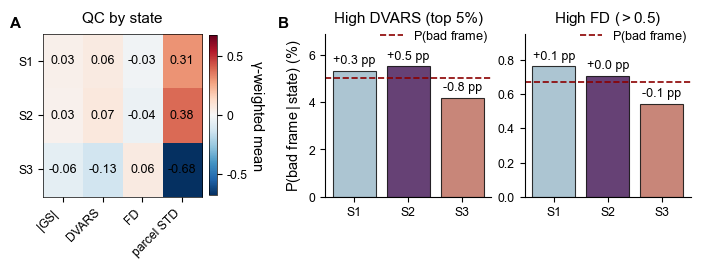

In [62]:
# Figure settings
figure_width_cm_qc, figure_height_cm_qc = 18.5, 6.0
title_fontsize_qc, axis_label_fontsize_qc = 11.0, 10.5
tick_fontsize_qc, annotation_fontsize_qc = 8.8, 9.0
panel_label_fontsize_qc = 11.0

previous_autolayout_qc = plt.rcParams["figure.autolayout"]
plt.rcParams["figure.autolayout"] = False

# Layout
fig_qc = plt.figure(figsize=(figure_width_cm_qc / 2.54, figure_height_cm_qc / 2.54))
outer_gs_qc = gridspec.GridSpec(1, 2, figure=fig_qc, width_ratios=[1.0, 2.1], wspace=0.4)

ax_signal_qc = fig_qc.add_subplot(outer_gs_qc[0])
bad_gs_qc = gridspec.GridSpecFromSubplotSpec(
    1, len(bad_order_qc), subplot_spec=outer_gs_qc[1], wspace=0.2
)
axes_bad_qc = [fig_qc.add_subplot(bad_gs_qc[0, j]) for j in range(len(bad_order_qc))]

fig_qc.subplots_adjust(left=0.08, right=0.97, bottom=0.19, top=0.88)

# Panel A: state-QC heatmap
values_qc = state_measure_qc.to_numpy(float)
vmax_qc = float(np.nanmax(np.abs(values_qc)))

im_qc = ax_signal_qc.imshow(
    values_qc, aspect="auto", cmap="RdBu_r", vmin=-vmax_qc, vmax=vmax_qc
)

ax_signal_qc.set_xticks(np.arange(len(measure_order_qc)))
ax_signal_qc.set_xticklabels(
    measure_labels_qc, rotation=45, ha="right", fontsize=tick_fontsize_qc
)
ax_signal_qc.set_yticks(np.arange(n_states_qc))
ax_signal_qc.set_yticklabels(state_order_qc, fontsize=tick_fontsize_qc)

for i in range(n_states_qc):
    for j in range(len(measure_order_qc)):
        ax_signal_qc.text(j, i, f"{values_qc[i, j]:.2f}",
                          ha="center", va="center", fontsize=annotation_fontsize_qc)

ax_signal_qc.set_title("QC by state", fontsize=title_fontsize_qc, pad=8)

for spine in ax_signal_qc.spines.values():
    spine.set_visible(True)
    spine.set_edgecolor("black")
    spine.set_linewidth(0.5)

cbar_qc = fig_qc.colorbar(im_qc, ax=ax_signal_qc, fraction=0.046, pad=0.04)
cbar_qc.set_ticks([-0.5, 0, 0.5])
cbar_qc.set_ticklabels(["-0.5", "0", "0.5"])
cbar_qc.set_label(r"$\gamma$-weighted mean",
                  fontsize=axis_label_fontsize_qc, rotation=270, labelpad=13)
cbar_qc.ax.tick_params(labelsize=tick_fontsize_qc)
cbar_qc.outline.set_linewidth(0.5)  # type: ignore

# Panel B: bad-frame probabilities
for j, bad_name_qc in enumerate(bad_order_qc):
    ax_qc = axes_bad_qc[j]
    d_qc = bad_prob_qc[bad_prob_qc["BadFrame"] == bad_name_qc].set_index("State").loc[state_order_qc]

    x_qc = np.arange(n_states_qc)
    y_qc = 100 * d_qc["soft_p_bad_given_state"].to_numpy(float)
    baseline_qc = 100 * float(d_qc["baseline_p_bad"].iloc[0])
    delta_pp_qc = d_qc["delta_percentage_points"].to_numpy(float)

    ax_qc.bar(x_qc, y_qc, color=colors_qc, alpha=0.8,
              edgecolor="black", linewidth=0.8)
    ax_qc.axhline(baseline_qc, color="darkred", linestyle="--",
                  linewidth=1.2, label=r"$P(\mathrm{bad\ frame})$")

    ymax_qc = max(np.nanmax(y_qc), baseline_qc) * 1.25
    offset_qc = 0.025 * ymax_qc

    for i in range(n_states_qc):
        ax_qc.text(x_qc[i], y_qc[i] + offset_qc, f"{delta_pp_qc[i]:+.1f} pp",
                   ha="center", va="bottom", fontsize=annotation_fontsize_qc,
                   bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=0.15),
                   clip_on=False)

    ax_qc.set_ylim(0, ymax_qc)
    ax_qc.set_xticks(x_qc)
    ax_qc.set_xticklabels(state_order_qc, fontsize=tick_fontsize_qc)
    ax_qc.set_title(bad_title_qc[bad_name_qc], fontsize=title_fontsize_qc, pad=8)
    ax_qc.set_ylabel(
        r"$P(\mathrm{bad\ frame}\,|\,\mathrm{state})$ (%)" if j == 0 else "",
        fontsize=axis_label_fontsize_qc
    )
    ax_qc.tick_params(axis="y", labelsize=tick_fontsize_qc)
    ax_qc.legend(frameon=False, loc=(0.3, 0.9),
                 fontsize=tick_fontsize_qc + 0.3, handlelength=1.8)
    ax_qc.spines["top"].set_visible(False)
    ax_qc.spines["right"].set_visible(False)

# Panel labels
fig_qc.canvas.draw()
pos_a_qc, pos_b_qc = ax_signal_qc.get_position(), axes_bad_qc[0].get_position()

fig_qc.text(pos_a_qc.x0 - 0.045, pos_a_qc.y1 + 0.015, "A",
            fontsize=panel_label_fontsize_qc, fontweight="bold",
            ha="left", va="bottom")
fig_qc.text(pos_b_qc.x0 - 0.065, pos_b_qc.y1 + 0.015, "B",
            fontsize=panel_label_fontsize_qc, fontweight="bold",
            ha="left", va="bottom")

# Save
tif_path = FIG_DIR / "SI_FigF.tif"
fig_qc.savefig(FIG_DIR / "SI_FigF.pdf", dpi=450, bbox_inches="tight")
fig_qc.savefig(tif_path, format="tiff", dpi=450, bbox_inches="tight", facecolor="white", transparent=False, pil_kwargs={"compression": "tiff_lzw"})
convert_tiff_to_rgb(tif_path, print_check=False, fig=fig_qc)

plt.show()
plt.rcParams["figure.autolayout"] = previous_autolayout_qc

### Robustness of OT-derived Clusters 

In [65]:
def load_cluster_assignments_stab(supp_dir, M_values, K_values, subjects_ms, zero_mean=True):
    '''
    Load MS OT cluster assignments across HMM configurations.
    '''
    model_name = "zeromean" if zero_mean else "freemean"
    subjects_ms = pd.Index(np.asarray(subjects_ms).astype(str), name="participant_id")
    labels = {}

    for M in M_values:
        for K in K_values:
            config = f"M{M}_K{K:02d}"
            path = Path(supp_dir) / config / model_name / "clusters_assignment.csv"

            df = pd.read_csv(path, usecols=["participant_id", "OT_cluster"])
            df["participant_id"] = df["participant_id"].astype(str)

            if df["participant_id"].duplicated().any():
                raise ValueError(f"Duplicated subjects in {config}")

            labels_config = df.set_index("participant_id")["OT_cluster"]
            missing = subjects_ms.difference(labels_config.index)
            extra = labels_config.index.difference(subjects_ms)

            if len(missing) or len(extra):
                raise ValueError(f"Subject mismatch in {config}: missing={missing.tolist()}, extra={extra.tolist()}")

            labels[config] = labels_config.reindex(subjects_ms).astype(int)

    return pd.DataFrame(labels, index=subjects_ms)

In [66]:
# Panel data
M_values_stab = [30, 40]
K_values_stab = [3, 4, 5, 6]

labels_df_stab = load_cluster_assignments_stab(SUPP_DATA_DIR, M_values_stab, K_values_stab, subjects[ms_mask], zero_mean=True)

configs_stab = labels_df_stab.columns.tolist()
ari_stab = np.eye(len(configs_stab))

for i, config_i in enumerate(configs_stab):
    for j in range(i + 1, len(configs_stab)):
        ari_stab[i, j] = ari_stab[j, i] = adjusted_rand_score(
            labels_df_stab[config_i], labels_df_stab[configs_stab[j]]
        )

ari_df_stab = pd.DataFrame(ari_stab, index=configs_stab, columns=configs_stab)

config_labels_stab = {f"M{M}_K{K:02d}": rf"$M={M},\,K={K}$" for M in M_values_stab for K in K_values_stab}
ari_plot_stab = ari_df_stab.rename(index=config_labels_stab, columns=config_labels_stab)

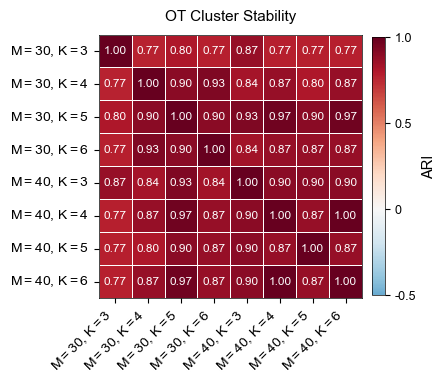

In [67]:
# Figure settings
figure_width_cm_stab, figure_height_cm_stab = 12, 12.5
title_fontsize_stab, tick_fontsize_stab = 11.0, 10.0
annotation_fontsize_stab = 8.5
cbar_label_fontsize_stab, cbar_tick_fontsize_stab = 10.5, 9.0

fig_stab, ax_stab = plt.subplots(
    figsize=(figure_width_cm_stab / 2.54, figure_height_cm_stab / 2.54),
    constrained_layout=False
)
fig_stab.subplots_adjust(left=0.20, right=0.88, bottom=0.20, top=0.90)

sns.heatmap(
    ari_plot_stab, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
    vmin=-0.5, vmax=1.0, square=True, linewidths=0.5, linecolor="white",
    annot_kws={"fontsize": annotation_fontsize_stab},
    cbar_kws={"label": "ARI", "shrink": 0.75, "pad": 0.03},
    ax=ax_stab
)

ax_stab.set_title("OT Cluster Stability", fontsize=title_fontsize_stab, pad=10)
ax_stab.set_xlabel("")
ax_stab.set_ylabel("")
ax_stab.tick_params(axis="x", labelrotation=45, labelsize=tick_fontsize_stab)
ax_stab.tick_params(axis="y", labelrotation=0, labelsize=tick_fontsize_stab)

for tick_stab in ax_stab.get_xticklabels():
    tick_stab.set_ha("right")  # type: ignore

for spine_stab in ax_stab.spines.values():
    spine_stab.set_visible(True)
    spine_stab.set_edgecolor("black")
    spine_stab.set_linewidth(0.5)

cbar_stab = ax_stab.collections[0].colorbar

if cbar_stab is not None:
    cbar_stab.set_ticks([-0.5, 0, 0.5, 1.0])
    cbar_stab.set_ticklabels(["-0.5", "0", "0.5", "1.0"])
    cbar_stab.set_label("ARI", fontsize=cbar_label_fontsize_stab, rotation=90)
    cbar_stab.ax.tick_params(labelsize=cbar_tick_fontsize_stab)

    if cbar_stab.outline is not None:
        cbar_stab.outline.set_edgecolor("black")  # type: ignore
        cbar_stab.outline.set_linewidth(0.5)  # type: ignore

tif_path = FIG_DIR / "SI_FigG.tif"
fig_stab.savefig(FIG_DIR / "SI_FigG.pdf", dpi=450, bbox_inches="tight")
fig_stab.savefig(tif_path, format="tiff", dpi=450, bbox_inches="tight", facecolor="white", transparent=False, pil_kwargs={"compression": "tiff_lzw"})
convert_tiff_to_rgb(tif_path, print_check=False, fig=fig_stab)

plt.show()

### HMM-based Clustering

In [75]:
def build_hmm_feature_matrix(df_hmm, Q_all, subjects, subject_mask, features=("fo", "q")):
    '''
    Build a subject-level HMM feature matrix from fractional occupancies and joint transition probabilities.
    '''
    features = [feature.lower() for feature in features]
    subjects = np.asarray(subjects).astype(str)
    subject_mask = np.asarray(subject_mask, bool)
    Q_all = np.asarray(Q_all, float)

    if Q_all.ndim != 3 or Q_all.shape[1] != Q_all.shape[2]:
        raise ValueError(f"Q_all must have shape subjects x states x states, found {Q_all.shape}.")
    if len(Q_all) != len(subjects) or len(subject_mask) != len(subjects):
        raise ValueError("Q_all, subjects and subject_mask have incompatible lengths.")

    df_hmm = df_hmm.copy()
    df_hmm["participant_id"] = df_hmm["participant_id"].astype(str)
    subjects_hmm = df_hmm["participant_id"].drop_duplicates().to_numpy()

    if not np.array_equal(subjects_hmm, subjects):
        raise ValueError("Subject order differs between HMM metrics and Q_all.")

    subjects_use = subjects[subject_mask]
    K = Q_all.shape[1]
    state_order = [f"State{k}" for k in range(K)]
    X_list = []

    if "fo" in features:
        fo = df_hmm.pivot(index="participant_id", columns="State", values="FO_soft").reindex(index=subjects_use, columns=state_order)
        fo.columns = [f"FO_S{k + 1}" for k in range(K)]
        X_list.append(fo)

    if "q" in features:
        Q_use = Q_all[subject_mask]
        if not np.allclose(Q_use.sum(axis=(1, 2)), 1.0, atol=1e-6):
            raise ValueError("Some Q matrices are not normalized.")

        q_columns = [f"Q_S{i + 1}S{j + 1}" for i in range(K) for j in range(K)]
        X_list.append(pd.DataFrame(Q_use.reshape(len(Q_use), -1), index=subjects_use, columns=q_columns))

    if not X_list:
        raise ValueError("No valid features selected.")

    X = pd.concat(X_list, axis=1).reindex(subjects_use)

    if X.isna().any().any():
        missing = X.index[X.isna().any(axis=1)].tolist()
        raise ValueError(f"Missing HMM features for subjects: {missing[:10]}")

    return X


def align_cluster_labels(labels, reference_labels):
    '''
    Align arbitrary cluster labels to a reference partition using maximum overlap.
    '''
    labels = np.asarray(labels, int)
    reference_labels = np.asarray(reference_labels, int)

    contingency = pd.crosstab(pd.Series(labels), pd.Series(reference_labels))
    rows, cols = linear_sum_assignment(-contingency.to_numpy())
    label_map = {contingency.index[i]: contingency.columns[j] for i, j in zip(rows, cols)}

    return np.asarray([label_map[label] for label in labels], int)

In [80]:
# Data
df_hmm_hmmfeat = main["hmm_metrics"].copy()
Q_all_hmmfeat = np.asarray(main["Q_all"], float)
df_ot_hmmfeat = main["clusters_assignment"].copy()

features_hmmfeat = ['fo', 'q']
n_pc_hmmfeat, k_cluster_hmmfeat = 6, 2

cluster_name_map_hmmfeat = {0: "Severe", 1: "Mild"}
cluster_order_hmmfeat = ["Severe", "Mild"]
state_map_hmmfeat = {f"State{k}": f"State {k + 1}" for k in range(selected_n_states)}
states_hmmfeat = list(state_map_hmmfeat.values())

# HMM feature matrix
X_hmmfeat = build_hmm_feature_matrix(df_hmm_hmmfeat, Q_all_hmmfeat, subjects, ms_mask, features=features_hmmfeat)
X_z_hmmfeat = StandardScaler().fit_transform(X_hmmfeat)

# PCA
pca_hmmfeat = PCA(n_components=None, svd_solver="full")
X_pca_all_hmmfeat = pca_hmmfeat.fit_transform(X_z_hmmfeat)
X_pca_hmmfeat = X_pca_all_hmmfeat[:, :n_pc_hmmfeat]

cumvar_hmmfeat = np.cumsum(pca_hmmfeat.explained_variance_ratio_)
pc_idx_hmmfeat = np.arange(1, len(cumvar_hmmfeat) + 1)
selected_cumvar_hmmfeat = cumvar_hmmfeat[n_pc_hmmfeat - 1]

# HMM-feature clustering
labels_raw_hmmfeat = AgglomerativeClustering(
    n_clusters=k_cluster_hmmfeat, metric="euclidean", linkage="ward"
).fit_predict(X_pca_hmmfeat).astype(int)

silhouette_hmmfeat = silhouette_score(X_pca_hmmfeat, labels_raw_hmmfeat)

# OT labels
df_ot_hmmfeat["participant_id"] = df_ot_hmmfeat["participant_id"].astype(str)
ot_labels_hmmfeat = df_ot_hmmfeat.set_index("participant_id").reindex(X_hmmfeat.index)["OT_cluster"]

if ot_labels_hmmfeat.isna().any():
    missing = ot_labels_hmmfeat.index[ot_labels_hmmfeat.isna()].tolist()
    raise ValueError(f"Missing OT labels for subjects: {missing[:10]}")

ot_labels_hmmfeat = ot_labels_hmmfeat.astype(int).to_numpy()

# Agreement with OT clustering
ari_hmmfeat = adjusted_rand_score(ot_labels_hmmfeat, labels_raw_hmmfeat)
nmi_hmmfeat = normalized_mutual_info_score(ot_labels_hmmfeat, labels_raw_hmmfeat)
labels_hmmfeat = align_cluster_labels(labels_raw_hmmfeat, ot_labels_hmmfeat)

df_hmmfeat_clusters = pd.DataFrame({
    "participant_id": X_hmmfeat.index,
    "HMM_feature_cluster": labels_hmmfeat,
    "OT_cluster": ot_labels_hmmfeat
})
df_hmmfeat_clusters["same_as_OT"] = df_hmmfeat_clusters["HMM_feature_cluster"] == df_hmmfeat_clusters["OT_cluster"]

# PCA plot dataframe
df_plot_hmmfeat = df_hmmfeat_clusters.copy()
df_plot_hmmfeat["PC1"] = X_pca_all_hmmfeat[:, 0]
df_plot_hmmfeat["PC2"] = X_pca_all_hmmfeat[:, 1]
df_plot_hmmfeat["Cluster"] = df_plot_hmmfeat["OT_cluster"].map(cluster_name_map_hmmfeat)
df_plot_hmmfeat["Cluster"] = pd.Categorical(df_plot_hmmfeat["Cluster"], categories=cluster_order_hmmfeat, ordered=True)

df_mismatch_hmmfeat = df_plot_hmmfeat.loc[~df_plot_hmmfeat["same_as_OT"]].copy()

# FO dataframe
df_fo_hmmfeat = df_hmm_hmmfeat.copy()
df_fo_hmmfeat["participant_id"] = df_fo_hmmfeat["participant_id"].astype(str)
df_fo_hmmfeat["State"] = df_fo_hmmfeat["State"].replace(state_map_hmmfeat)

df_fo_hmmfeat = df_fo_hmmfeat.merge(
    df_hmmfeat_clusters[["participant_id", "OT_cluster"]],
    on="participant_id", how="inner", validate="many_to_one"
)
df_fo_hmmfeat["Cluster"] = df_fo_hmmfeat["OT_cluster"].map(cluster_name_map_hmmfeat)
df_fo_hmmfeat["Cluster"] = pd.Categorical(df_fo_hmmfeat["Cluster"], categories=cluster_order_hmmfeat, ordered=True)

print(f"ARI vs OT: {ari_hmmfeat:.3f}")
print(f'Normalized Mutual Information vs OT: {nmi_hmmfeat:.3f}')

ARI vs OT: 1.000
Normalized Mutual Information vs OT: 1.000


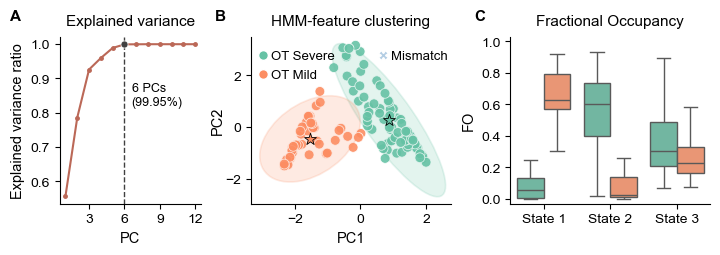

In [81]:
# Figure settings
figure_width_cm_hmmfeat, figure_height_cm_hmmfeat = 18.0, 6.2
title_fontsize_hmmfeat, axis_label_fontsize_hmmfeat = 11.0, 10.5
tick_fontsize_hmmfeat, legend_fontsize_hmmfeat = 10.0, 9.5
panel_label_fontsize_hmmfeat = 11.0

cluster_palette_hmmfeat = dict(zip(cluster_order_hmmfeat, sns.color_palette("Set2", n_colors=2)))
mismatch_color_hmmfeat = "#b3cde3"
cum_color_hmmfeat = plt.cm.twilight(0.78)  # type: ignore

previous_autolayout = plt.rcParams["figure.autolayout"]
plt.rcParams["figure.autolayout"] = False

# Figure
fig, axd = plt.subplot_mosaic(
    [["A", "B", "C"]],
    figsize=(figure_width_cm_hmmfeat / 2.54, figure_height_cm_hmmfeat / 2.54),
    constrained_layout=True, gridspec_kw={"width_ratios": [0.85, 1.2, 1.2]}
)

# Panel A: explained variance
ax = axd["A"]
ax.plot(pc_idx_hmmfeat, cumvar_hmmfeat, "o-", color=cum_color_hmmfeat, linewidth=1.5, markersize=2.5)
ax.axvline(n_pc_hmmfeat, color="0.25", linestyle="--", linewidth=1.0)
ax.scatter(n_pc_hmmfeat, selected_cumvar_hmmfeat, s=26, color="0.25",
           edgecolor="white", linewidth=0.5, zorder=5)

ax.annotate(f"{n_pc_hmmfeat} PCs\n({100 * selected_cumvar_hmmfeat:.2f}%)",
            xy=(n_pc_hmmfeat, selected_cumvar_hmmfeat),
            xytext=(n_pc_hmmfeat + 0.6, selected_cumvar_hmmfeat - 0.11),
            fontsize=9, ha="left", va="top")

ax.set_xlim(0.5, len(pc_idx_hmmfeat) + 0.5)
ax.set_xticks([3, 6, 9, 12])
ax.set_title("Explained variance", fontsize=title_fontsize_hmmfeat, pad=8)
ax.set_xlabel("PC", fontsize=axis_label_fontsize_hmmfeat)
ax.set_ylabel("Explained variance ratio", fontsize=axis_label_fontsize_hmmfeat)
ax.tick_params(axis="both", labelsize=tick_fontsize_hmmfeat)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Panel B: HMM-feature clustering
ax = axd["B"]

sns.scatterplot(data=df_plot_hmmfeat, x="PC1", y="PC2", hue="Cluster",
                hue_order=cluster_order_hmmfeat, palette=cluster_palette_hmmfeat,
                edgecolor="white", linewidth=0.6, s=50, alpha=0.9, legend=False, ax=ax)

for cluster in cluster_order_hmmfeat:
    d = df_plot_hmmfeat[df_plot_hmmfeat["Cluster"] == cluster]
    add_cov_ellipse(ax, d["PC1"].to_numpy(), d["PC2"].to_numpy(), cluster_palette_hmmfeat[cluster])

if not df_mismatch_hmmfeat.empty:
    ax.scatter(df_mismatch_hmmfeat["PC1"], df_mismatch_hmmfeat["PC2"], marker="X", s=70,
               color=mismatch_color_hmmfeat, edgecolor="white", linewidth=0.6, zorder=5)

legend_handles_hmmfeat = [
    Line2D([0], [0], marker="o", linestyle="", markersize=7, label=f"OT {cluster}",
           markerfacecolor=cluster_palette_hmmfeat[cluster], markeredgecolor="white")
    for cluster in cluster_order_hmmfeat
]
legend_handles_hmmfeat.append(
    Line2D([0], [0], marker="X", linestyle="", markersize=7, label="Mismatch",
           markerfacecolor=mismatch_color_hmmfeat, markeredgecolor="white")
)

ax.set_xlabel("PC1", fontsize=axis_label_fontsize_hmmfeat)
ax.set_ylabel("PC2", fontsize=axis_label_fontsize_hmmfeat, labelpad=0)
ax.set_title("HMM-feature clustering", fontsize=title_fontsize_hmmfeat, pad=8)
ax.tick_params(axis="both", labelsize=tick_fontsize_hmmfeat)
ax.legend(handles=legend_handles_hmmfeat, frameon=False, fontsize=legend_fontsize_hmmfeat,
          loc="upper center", bbox_to_anchor=(0.51, 0.99), ncol=2,
          handletextpad=0.2, columnspacing=3.3, handlelength=0.8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Panel C: fractional occupancy
ax = axd["C"]
sns.boxplot(data=df_fo_hmmfeat, x="State", y="FO_soft", hue="Cluster",
            order=states_hmmfeat, hue_order=cluster_order_hmmfeat,
            palette=cluster_palette_hmmfeat, showfliers=False, ax=ax)

ax.set_xlabel("")
ax.set_ylabel("FO", fontsize=axis_label_fontsize_hmmfeat)
ax.set_ylim(-0.03, 1.03)
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.set_title("Fractional Occupancy", fontsize=title_fontsize_hmmfeat, pad=8)
ax.tick_params(axis="both", labelsize=tick_fontsize_hmmfeat)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

if ax.get_legend() is not None:
    ax.get_legend().remove()

# Panel labels
for key in ["A", "B", "C"]:
    axd[key].text(-0.18 if key != "A" else -0.35, 1.08, key,
                  transform=axd[key].transAxes, fontsize=panel_label_fontsize_hmmfeat,
                  fontweight="bold", ha="left", va="bottom")

# Save
tif_path = FIG_DIR / "SI_FigH.tif"
fig.savefig(FIG_DIR / "SI_FigH.pdf", dpi=450, bbox_inches="tight")
fig.savefig(tif_path, format="tiff", dpi=450, bbox_inches="tight",facecolor="white", transparent=False, pil_kwargs={"compression": "tiff_lzw"})
convert_tiff_to_rgb(tif_path, print_check=False, fig=fig)

plt.show()
plt.rcParams["figure.autolayout"] = previous_autolayout

### Non-zero Mean States

In [87]:
def match_hmm_states(reference_fcs, target_fcs):
    '''
    Match HMM states by maximizing state-wise FC similarity.
    '''
    reference_fcs = np.asarray(reference_fcs, float)
    target_fcs = np.asarray(target_fcs, float)
    idx = np.triu_indices(reference_fcs.shape[1], k=1)

    similarity = np.array([
        [np.corrcoef(reference_fcs[i][idx], target_fcs[j][idx])[0, 1]
         for j in range(len(target_fcs))]
        for i in range(len(reference_fcs))
    ])

    ref_idx, target_idx = linear_sum_assignment(-similarity)
    order = target_idx[np.argsort(ref_idx)]

    return order, similarity

In [89]:
# Panel data
free_mean = load_supp_results(SUPP_DATA_DIR, M=30, K=3, zero_mean=False)

means_free = np.asarray(free_mean["means_orig"], float)
fcs_free = np.asarray(free_mean["fcs_orig"], float)

state_order_free, state_similarity_free = match_hmm_states(main["fcs_orig"], fcs_free)
means_free = means_free[state_order_free]
fcs_free = fcs_free[state_order_free]

print("Free-mean state order:", state_order_free.tolist())
print("Matched FC correlations:",
      [f"{state_similarity_free[k, state_order_free[k]]:.3f}" for k in range(selected_n_states)])

n_states_free, n_parc_free = means_free.shape
mean_titles_free = [f"Mean - State {k + 1}" for k in range(n_states_free)]
fc_titles_free = [f"FC - State {k + 1}" for k in range(n_states_free)]

mean_range_free = symmetric_percentile_range(means_free, percentile=99)
fc_vmax_free = np.percentile(np.abs(fcs_free), 99)
fc_vminvmax_free = [[-fc_vmax_free, fc_vmax_free] for _ in range(n_states_free)]

surfaces_free = fetch_fslr()
lh_surf_free, rh_surf_free = surfaces_free["veryinflated"]
lh_parc_free, rh_parc_free = load_parcellation("schaefer", scale=n_parc_free)

rendered_means_free = [
    render_surface_image(
        means_free[k], n_parc_free, lh_surf_free, rh_surf_free,
        lh_parc_free, rh_parc_free, surface_space="conte69",
        cmap="RdBu_r", color_range=mean_range_free, dpi=350
    )
    for k in range(n_states_free)
]

Free-mean state order: [2, 0, 1]
Matched FC correlations: ['1.000', '1.000', '1.000']


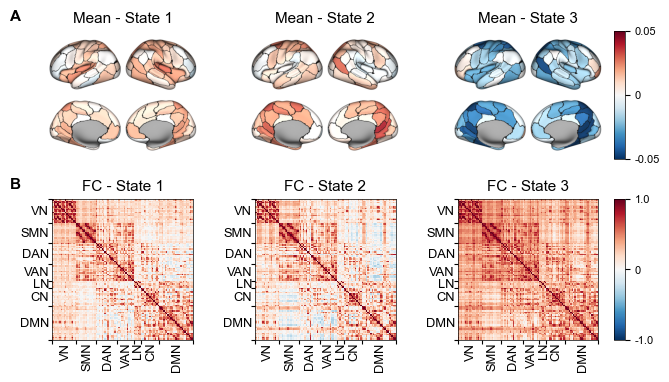

In [91]:
# Figure settings
figure_width_cm_free, figure_height_cm_free = 18, 9.0
title_fontsize_free, tick_fontsize_free = 11.0, 8.0
panel_label_fontsize_free = 11.0

fig_free = plt.figure(figsize=(figure_width_cm_free / 2.54, figure_height_cm_free / 2.54))
gs_free = gridspec.GridSpec(2, n_states_free, figure=fig_free, height_ratios=[1.0, 1.1], hspace=0.3, wspace=-0.2)

axes_mean_free = [fig_free.add_subplot(gs_free[0, i]) for i in range(n_states_free)]
axes_fc_free = [fig_free.add_subplot(gs_free[1, i]) for i in range(n_states_free)]

fig_free.subplots_adjust(left=0.00, right=0.93, bottom=0.08, top=0.95)

# Mean activity
for ax, img, title in zip(axes_mean_free, rendered_means_free, mean_titles_free):
    ax.imshow(img)
    ax.axis("off")
    ax.set_title(title, fontsize=title_fontsize_free, pad=6)

# FC matrices
plot_matrices(list(fcs_free), network_labels=network_labels, network_names=network_names, titles=fc_titles_free, 
              vminvmax=fc_vminvmax_free, center=0, cmap="RdBu_r", figsize_per_matrix=(2.9, 2.8), sort=True, 
              labels_for=list(range(n_states_free)), label_pad_x=2.2, label_pad_y=2.2, label_size=3.2, 
              x_label_shift=0.82, y_label_shift=0.82, axes=axes_fc_free, cbar=False)

for ax, title in zip(axes_fc_free, fc_titles_free):
    ax.set_title(title, fontsize=title_fontsize_free, pad=6)

# Colorbars
fig_free.canvas.draw()
pos_mean_free = axes_mean_free[-1].get_position()
pos_fc_free = axes_fc_free[-1].get_position()
cbar_x_free = max(pos_mean_free.x1, pos_fc_free.x1) + 0.01

cax_mean_free = fig_free.add_axes([cbar_x_free, pos_mean_free.y0, 0.015, pos_mean_free.height])  # type: ignore
sm_mean_free = cm.ScalarMappable(norm=Normalize(vmin=mean_range_free[0], vmax=mean_range_free[1]), cmap="RdBu_r")
sm_mean_free.set_array([])

cbar_mean_free = fig_free.colorbar(sm_mean_free, cax=cax_mean_free)
cbar_mean_free.set_ticks([mean_range_free[0], 0, mean_range_free[1]])
cbar_mean_free.set_ticklabels([f"{mean_range_free[0]:.2f}", "0", f"{mean_range_free[1]:.2f}"])
cbar_mean_free.ax.tick_params(labelsize=tick_fontsize_free)
cbar_mean_free.outline.set_edgecolor("black")  # type: ignore
cbar_mean_free.outline.set_linewidth(0.5)  # type: ignore

cax_fc_free = fig_free.add_axes([cbar_x_free, pos_fc_free.y0, 0.015, pos_fc_free.height])  # type: ignore
cbar_fc_free = fig_free.colorbar(axes_fc_free[0].collections[0], cax=cax_fc_free)
cbar_fc_free.set_ticks([-fc_vmax_free, 0, fc_vmax_free])  # type: ignore
cbar_fc_free.set_ticklabels([f"{-fc_vmax_free:.1f}", "0", f"{fc_vmax_free:.1f}"])
cbar_fc_free.ax.tick_params(labelsize=tick_fontsize_free)
cbar_fc_free.outline.set_edgecolor("black")  # type: ignore
cbar_fc_free.outline.set_linewidth(0.5)  # type: ignore

# Panel labels
fig_free.canvas.draw()
y_a_free = max(ax.get_position().y1 for ax in axes_mean_free) + 0.021
y_b_free = max(ax.get_position().y1 for ax in axes_fc_free) + 0.021

fig_free.text(0.02, y_a_free, "A", fontsize=panel_label_fontsize_free,
              fontweight="bold", ha="left", va="bottom")
fig_free.text(0.02, y_b_free, "B", fontsize=panel_label_fontsize_free,
              fontweight="bold", ha="left", va="bottom")

# Save
tif_path = FIG_DIR / "SI_FigI.tif"
fig_free.savefig(FIG_DIR / "SI_FigI.pdf", dpi=450, bbox_inches="tight")
fig_free.savefig(tif_path, format="tiff", dpi=450, bbox_inches="tight", facecolor="white", transparent=False,pil_kwargs={"compression": "tiff_lzw"})
convert_tiff_to_rgb(tif_path, print_check=False, fig=fig_free)

plt.show()